# 02 · Material EDA — composition → properties → degradation → failure

Every plot or test below answers a stated question. The audit (notebook 01) showed that README physics constraints are violated in DS1,
that DS1 cannot be keyed to DS3/DS6, and that DS6 contains only failures. So this EDA is organised to test, with evidence:

| Part | Data | Core question |
|---|---|---|
| **A** | DS1 (5,500 compounds) | Do properties follow composition and physics, or are they driven by labels? |
| **B** | DS3 (5,000 bridges) | What drives corrosion, thinning and condition rating? |
| **C** | DS6 (2,000 failures) vs DS3 | Which material/degradation features are over-represented among failures? |

Statistical conventions: rank-based effect sizes (Cliff's δ: |δ|<0.147 negligible, <0.33 small, <0.474 medium), Benjamini–Hochberg FDR across
families of tests, η² / ε² for variance explained by categories. Nothing is removed or imputed; raw data are untouched.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats as sps
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))
from src.data import audit as A
from src.utils import stats as S

RAW, TAB, FIG = ROOT/"data/raw", ROOT/"outputs/tables", ROOT/"outputs/figures"
for p in (TAB, FIG): p.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")
SEED = 42
rng = np.random.default_rng(SEED)
KEY = {}   # key numeric findings, saved at the end

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

def note(key, value, text):
    """Record a computed finding (shown in the final summary and saved to CSV)."""
    KEY[key] = {"value": value, "meaning": text}

from src.materials import composition as comp_mod
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
import statsmodels.formula.api as smf

dfs = A.load_csvs(RAW); xl = A.load_xlsx_blocks(RAW / A.XLSX_FILE)
d1, d3, d6 = dfs["DS1"].copy(), dfs["DS3"].copy(), dfs["DS6"].copy()
d1["row_id"] = np.arange(len(d1))          # material_id is NOT unique (audit rule DS1-01)
TARGETS = {"formation_energy_per_atom_eV": "Formation energy (eV/atom)", "energy_above_hull_eV": "Energy above hull (eV)",
           "band_gap_eV": "Band gap (eV)", "bulk_modulus_GPa": "Bulk modulus K (GPa)", "shear_modulus_GPa": "Shear modulus G (GPa)",
           "poisson_ratio": "Poisson ratio", "density_g_cm3": "Density (g/cm3)", "melting_point_K": "Melting point (K)"}
print({k: v.shape for k, v in (("DS1", d1), ("DS3", d3), ("DS6", d6))})

{'DS1': (5500, 19), 'DS3': (5000, 24), 'DS6': (2000, 18)}


# PART A — DS1: crystalline material properties
## A1 · Shape of each property distribution
*Question: which targets are skewed/bounded enough to need a transform, and where is there a point mass (e.g. band gap = 0)?*

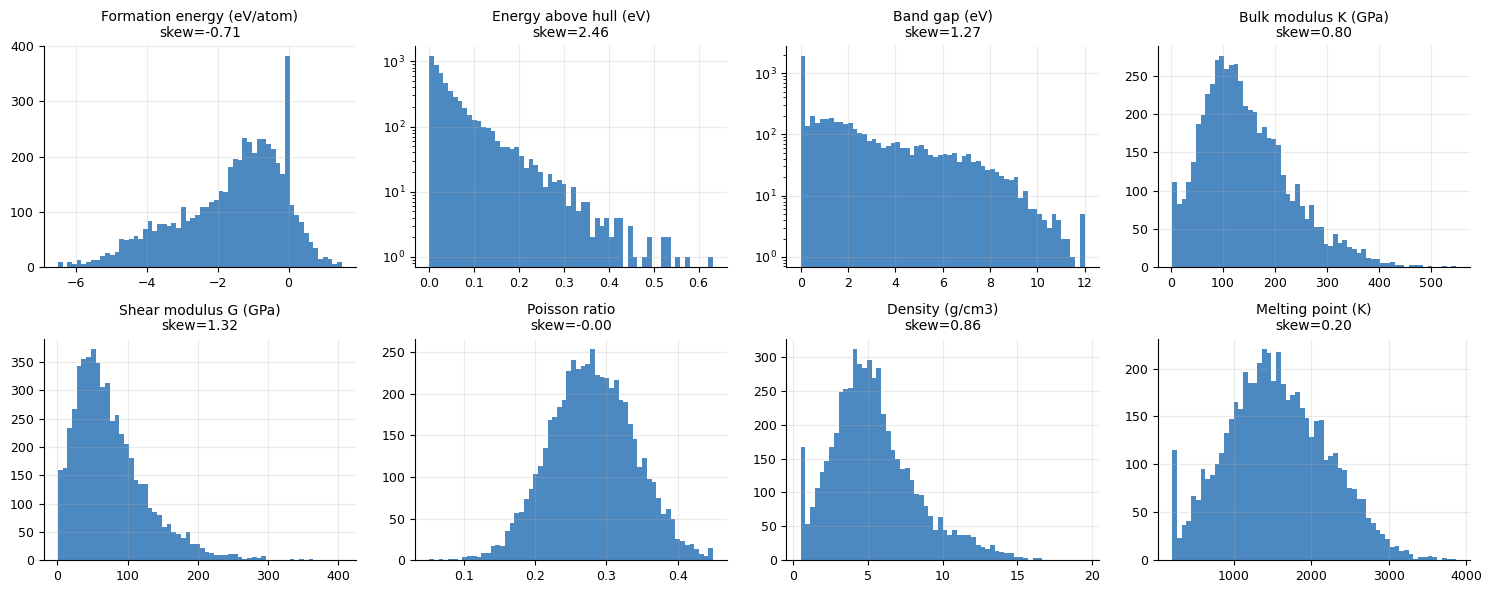

,skew,excess_kurtosis,share_exactly_zero,min,median,max,share_at_min,share_at_max,transform_hint
formation_energy_per_atom_eV,-0.714,-0.101,0.042,-6.500,-1.265,1.500,0.001,0.001,none needed
energy_above_hull_eV,2.458,8.165,0.002,0.000,0.032,0.633,0.002,0.000,right-skewed: log/log1p
band_gap_eV,1.272,0.801,0.325,0.000,1.169,12.000,0.325,0.001,right-skewed: log/log1p
bulk_modulus_GPa,0.803,0.597,0.000,2.000,130.445,548.200,0.012,0.000,none needed
shear_modulus_GPa,1.322,2.544,0.000,0.500,64.660,405.220,0.001,0.000,right-skewed: log/log1p
poisson_ratio,-0.000,-0.098,0.000,0.051,0.279,0.450,0.000,0.002,none needed
density_g_cm3,0.858,0.918,0.000,0.500,5.004,19.512,0.023,0.000,none needed
melting_point_K,0.198,-0.319,0.000,200.000,1519.000,3868.000,0.016,0.000,none needed


In [2]:
cols = list(TARGETS)
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(d1[c], bins=60, color="#2e75b6", alpha=.85); ax.set_title(f"{TARGETS[c]}\nskew={d1[c].skew():.2f}")
    ax.set_yscale("log") if c in ("band_gap_eV","energy_above_hull_eV") else None
savefig("A1_ds1_distributions.png")
sk = pd.DataFrame({"skew": d1[cols].skew(), "excess_kurtosis": d1[cols].kurt(), "share_exactly_zero": (d1[cols] == 0).mean(),
                   "min": d1[cols].min(), "median": d1[cols].median(), "max": d1[cols].max(),
                   "share_at_min": (d1[cols] == d1[cols].min()).mean(), "share_at_max": (d1[cols] == d1[cols].max()).mean()}).round(3)
sk["transform_hint"] = np.where(sk["skew"] > 1, "right-skewed: log/log1p", np.where(sk["skew"] < -1, "left-skewed", "none needed"))
sk.to_csv(TAB / "A1_ds1_distribution_summary.csv"); display(sk)
note("ds1_density_share_at_floor", float(sk.loc["density_g_cm3", "share_at_min"]), "share of rows piled at the minimum density (value clipped at a bound -> censored)")
note("ds1_G_share_at_floor", float(sk.loc["shear_modulus_GPa", "share_at_min"]), "share of rows piled at the minimum shear modulus")
note("ds1_band_gap_zero_share", float((d1.band_gap_eV == 0).mean()), "share of DS1 with band gap exactly 0 (metals) -> two-part target (metal flag + gap)")

## A2 · Do categorical labels organise the properties?
*Question: how much of each property's variance is explained by `category`, `crystal_system`, `n_elements`, `is_metal`?
(Null expectation for η² with k groups and n rows is ≈ (k−1)/(n−1); for 15 categories ≈ 0.003.)*

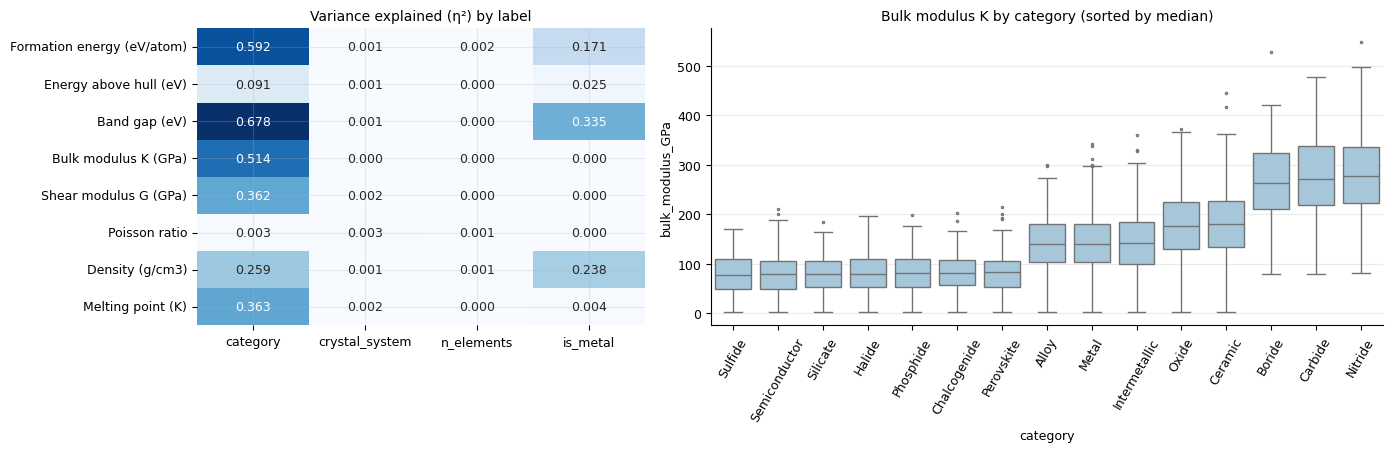

,category,crystal_system,n_elements,is_metal
Formation energy (eV/atom),0.592,0.001,0.002,0.171
Energy above hull (eV),0.091,0.001,0.000,0.025
Band gap (eV),0.678,0.001,0.000,0.335
Bulk modulus K (GPa),0.514,0.000,0.000,0.000
Shear modulus G (GPa),0.362,0.002,0.000,0.000
Poisson ratio,0.003,0.003,0.001,0.000
Density (g/cm3),0.259,0.001,0.001,0.238
Melting point (K),0.363,0.002,0.000,0.004


In [3]:
groupers = {"category": d1.category, "crystal_system": d1.crystal_system, "n_elements": d1.n_elements, "is_metal": d1.is_metal}
eta = pd.DataFrame({g: {TARGETS[t]: S.eta_squared(d1[t], v) for t in cols} for g, v in groupers.items()}).round(3)
eta.to_csv(TAB / "A2_ds1_eta_squared.csv")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
sns.heatmap(eta, annot=True, fmt=".3f", cmap="Blues", vmin=0, ax=ax[0], cbar=False); ax[0].set_title("Variance explained (η²) by label")
order = d1.groupby("category").bulk_modulus_GPa.median().sort_values().index
sns.boxplot(data=d1, x="category", y="bulk_modulus_GPa", order=order, ax=ax[1], color="#9ecae1", fliersize=1.5)
ax[1].tick_params(axis="x", rotation=60); ax[1].set_title("Bulk modulus K by category (sorted by median)")
savefig("A2_ds1_label_variance.png")
display(eta)
note("ds1_eta2_category_K", float(eta.loc["Bulk modulus K (GPa)", "category"]), "variance of K explained by category")
note("ds1_eta2_category_density", float(eta.loc["Density (g/cm3)", "category"]), "variance of density explained by category")
note("ds1_eta2_category_Ef", float(eta.loc["Formation energy (eV/atom)", "category"]), "variance of formation energy explained by category")

## A3 · Are the category labels consistent with the chemistry?
*Question: if `category` were assigned from composition (an oxide contains O, a nitride contains N, …) the consistency rate would be ≈100%.
Compare each rule's hit-rate inside the category with its base rate outside it (lift = 1 means the label carries no chemical information).*

,category,n,rule,share_in_category,base_rate_elsewhere,lift
0,Metal,1010,is_metal == 1,1.000,0.173,5.764
1,Intermetallic,451,is_metal == 1,1.000,0.265,3.774
2,Alloy,328,is_metal == 1,1.000,0.282,3.540
3,Semiconductor,547,0 < gap <= 4 eV,1.000,0.406,2.464
4,Perovskite,215,contains O and >=3 elements,0.033,0.020,1.623
5,Ceramic,471,band gap > 0,1.000,0.644,1.552
6,Chalcogenide,249,contains S/Se/Te,0.124,0.113,1.102
7,Phosphide,157,contains P,0.038,0.037,1.031
8,Boride,107,contains B,0.037,0.038,0.993
9,Oxide,773,contains O,0.038,0.039,0.964


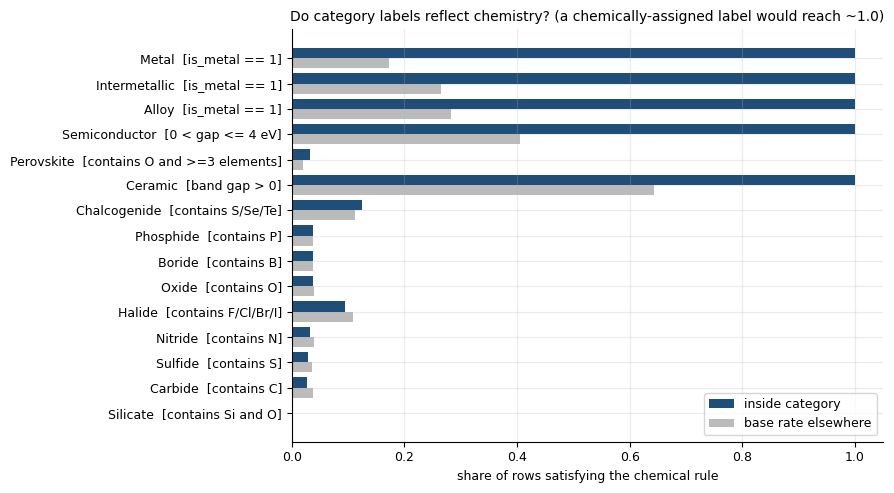

In [4]:
elsets = [set(A.parse_elements(f)) for f in d1.formula]
has    = lambda *e: np.array([bool(s & set(e)) for s in elsets])
hasall = lambda *e: np.array([set(e) <= s for s in elsets])
gap = d1.band_gap_eV.values
EXP = {"Oxide": ("contains O", has("O")), "Nitride": ("contains N", has("N")), "Carbide": ("contains C", has("C")),
       "Sulfide": ("contains S", has("S")), "Boride": ("contains B", has("B")), "Phosphide": ("contains P", has("P")),
       "Halide": ("contains F/Cl/Br/I", has("F", "Cl", "Br", "I")), "Silicate": ("contains Si and O", hasall("Si", "O")),
       "Chalcogenide": ("contains S/Se/Te", has("S", "Se", "Te")), "Perovskite": ("contains O and >=3 elements", has("O") & (d1.n_elements.values >= 3)),
       "Metal": ("is_metal == 1", d1.is_metal.values == 1), "Alloy": ("is_metal == 1", d1.is_metal.values == 1),
       "Intermetallic": ("is_metal == 1", d1.is_metal.values == 1), "Semiconductor": ("0 < gap <= 4 eV", (gap > 0) & (gap <= 4)),
       "Ceramic": ("band gap > 0", gap > 0)}
rows = []
for cat, (rule, ok) in EXP.items():
    m = (d1.category == cat).values
    rows.append({"category": cat, "n": int(m.sum()), "rule": rule, "share_in_category": ok[m].mean(), "base_rate_elsewhere": ok[~m].mean()})
cc = pd.DataFrame(rows); cc["lift"] = cc.share_in_category / cc.base_rate_elsewhere
cc = cc.sort_values("lift", ascending=False).round(3).reset_index(drop=True); cc.to_csv(TAB / "A3_category_chemistry_consistency.csv", index=False); display(cc)
fig, ax = plt.subplots(figsize=(9, 5)); y = np.arange(len(cc))
ax.barh(y - .2, cc.share_in_category, .4, label="inside category", color="#1f4e79"); ax.barh(y + .2, cc.base_rate_elsewhere, .4, label="base rate elsewhere", color="#bbb")
ax.set_yticks(y); ax.set_yticklabels(cc.category + "  [" + cc.rule + "]"); ax.invert_yaxis(); ax.legend(); ax.set_xlabel("share of rows satisfying the chemical rule")
ax.set_title("Do category labels reflect chemistry? (a chemically-assigned label would reach ~1.0)")
savefig("A3_category_chemistry.png")
note("ds1_oxide_contains_O", float(cc.set_index("category").loc["Oxide", "share_in_category"]), "share of 'Oxide' rows whose formula contains oxygen")
note("ds1_median_label_lift", float(cc.lift.median()), "median lift of chemistry rules inside category vs elsewhere (1 = no information)")

## A4 · Does composition drive the properties? (physics identities + element effects)
Atomic masses and atomic numbers come from pymatgen's element database.

*Question 1: the data dictionary says density is "computed from unit cell volume and composition" — ρ = n·m̄·u / V.
Does the supplied density obey it?* 
*Question 2: do `nsites` agree with the reduced formula (a cell must hold an integer number of formula units)?*

observed/implied density: median=2.35  p5=0.16  p95=18.01
rows within ±10% of physically implied density: 4.7%
Spearman(observed density, mean atomic mass) = +0.004
Spearman(observed density, implied density)   = -0.633
nsites is an integer multiple of atoms-in-reduced-formula: 30.6% of rows


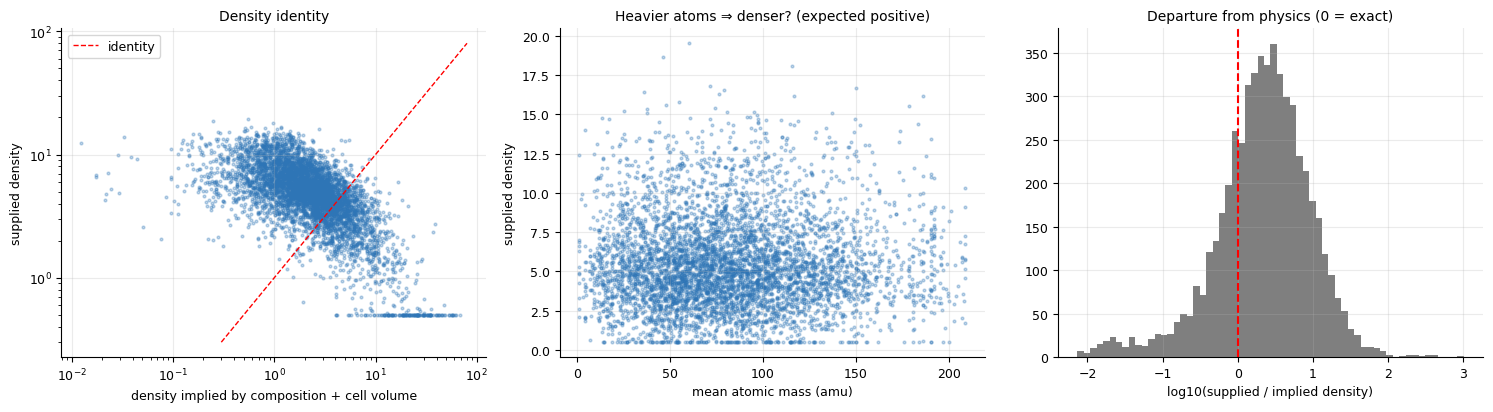

In [5]:
comp = comp_mod.composition_table(d1.formula)
d1 = pd.concat([d1, comp], axis=1)
d1["density_implied"] = comp_mod.density_from_cell(d1.nsites, d1.mean_atomic_mass, d1.volume_A3)
ratio = d1.density_g_cm3 / d1.density_implied
within10 = float((ratio.sub(1).abs() < 0.10).mean())
mult = float((d1.nsites % d1.atoms_per_formula == 0).mean())
print(f"observed/implied density: median={ratio.median():.2f}  p5={ratio.quantile(.05):.2f}  p95={ratio.quantile(.95):.2f}")
print(f"rows within ±10% of physically implied density: {100*within10:.1f}%")
print(f"Spearman(observed density, mean atomic mass) = {sps.spearmanr(d1.density_g_cm3, d1.mean_atomic_mass)[0]:+.3f}")
print(f"Spearman(observed density, implied density)   = {sps.spearmanr(d1.density_g_cm3, d1.density_implied)[0]:+.3f}")
print(f"nsites is an integer multiple of atoms-in-reduced-formula: {100*mult:.1f}% of rows")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(d1.density_implied, d1.density_g_cm3, s=4, alpha=.3, color="#2e75b6"); lim = [0.3, 80]
ax[0].plot(lim, lim, "r--", lw=1, label="identity"); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].legend()
ax[0].set_xlabel("density implied by composition + cell volume"); ax[0].set_ylabel("supplied density"); ax[0].set_title("Density identity")
ax[1].scatter(d1.mean_atomic_mass, d1.density_g_cm3, s=4, alpha=.3, color="#2e75b6"); ax[1].set_xlabel("mean atomic mass (amu)"); ax[1].set_ylabel("supplied density"); ax[1].set_title("Heavier atoms ⇒ denser? (expected positive)")
ax[2].hist(np.log10(ratio), bins=60, color="#7f7f7f"); ax[2].axvline(0, color="r", ls="--"); ax[2].set_xlabel("log10(supplied / implied density)"); ax[2].set_title("Departure from physics (0 = exact)")
savefig("A4_density_identity.png")
note("ds1_density_within10pct_of_physics", within10, "share of rows whose density is within 10% of density implied by composition and volume")
note("ds1_nsites_multiple_of_formula", mult, "share of rows where nsites is an integer multiple of the reduced-formula atom count")
note("ds1_spearman_density_vs_mass", float(sps.spearmanr(d1.density_g_cm3, d1.mean_atomic_mass)[0]), "Spearman(density, mean atomic mass); physics predicts strongly positive")

*Question 3: element by element, does the presence of an element shift any property? (Cliff's δ present-vs-absent, BH-FDR over all element×property tests; elements in ≥100 materials.)*

62 elements × 8 properties = 496 tests | q<0.05: 0 (0.0%; ~25 expected by chance if no signal)
tests with at least a SMALL effect (|δ|>=0.147): 0 | max |δ| = 0.145


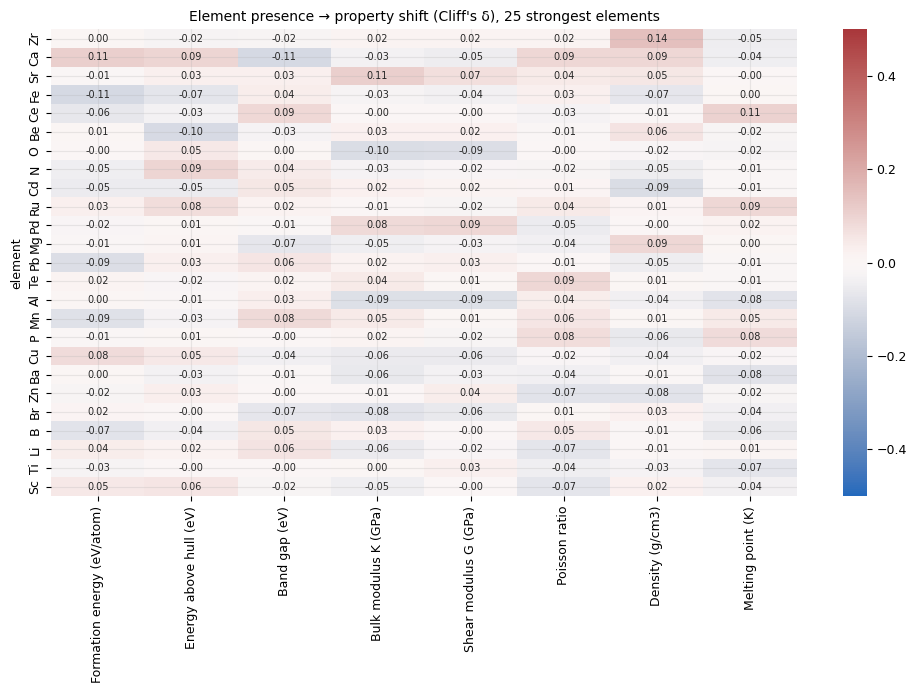

Spearman(element atomic number Z, element's density effect δ) = +0.053 (p=0.685); physics predicts strongly positive


In [6]:
pres = comp_mod.element_presence(d1.formula, min_count=100)
rows = []
for el in pres.columns:
    m = pres[el].values
    for t in cols:
        dl, p = S.cliffs_delta(d1.loc[m, t], d1.loc[~m, t]); rows.append((el, t, dl, p, int(m.sum())))
eff = pd.DataFrame(rows, columns=["element", "target", "delta", "p", "n_with"]); eff["q"] = S.bh_fdr(eff.p)
eff.to_csv(TAB / "A4_element_effects.csv", index=False)
n_t = len(eff); sig = int((eff.q < 0.05).sum()); big = int((eff.delta.abs() >= 0.147).sum())
print(f"{pres.shape[1]} elements × {len(cols)} properties = {n_t} tests | q<0.05: {sig} ({100*sig/n_t:.1f}%; ~{0.05*n_t:.0f} expected by chance if no signal)")
print(f"tests with at least a SMALL effect (|δ|>=0.147): {big} | max |δ| = {eff.delta.abs().max():.3f}")
pv = eff.pivot(index="element", columns="target", values="delta")[cols]; pv.columns = [TARGETS[c] for c in pv.columns]
top = pv.abs().max(axis=1).sort_values(ascending=False).head(25).index
fig, ax = plt.subplots(figsize=(10, 7)); sns.heatmap(pv.loc[top], cmap="vlag", center=0, vmin=-.5, vmax=.5, annot=True, fmt=".2f", ax=ax, annot_kws={"size": 7})
ax.set_title("Element presence → property shift (Cliff's δ), 25 strongest elements"); savefig("A4_element_effects.png")
# physics probe: heavier elements should raise density
Zs = pd.Series({el: comp_mod.Element(el).Z for el in pres.columns})
dens = eff[eff.target == "density_g_cm3"].set_index("element").delta
rZ = sps.spearmanr(Zs.loc[dens.index], dens)
print(f"Spearman(element atomic number Z, element's density effect δ) = {rZ[0]:+.3f} (p={rZ[1]:.3g}); physics predicts strongly positive")
note("ds1_element_tests_significant_share", sig / n_t, "share of element×property tests with q<0.05 (chance level 0.05)")
note("ds1_max_abs_element_delta", float(eff.delta.abs().max()), "largest element-presence effect size (Cliff's delta)")
note("ds1_Z_vs_density_effect", float(rZ[0]), "do heavier elements raise density in DS1? Spearman(Z, delta_density)")

*Question 4: how much can label-free composition descriptors explain vs. a category-mean lookup? (Group-K-fold by formula, so duplicates cannot leak; this is a diagnostic, not the final model — those are in the modelling notebook.)*

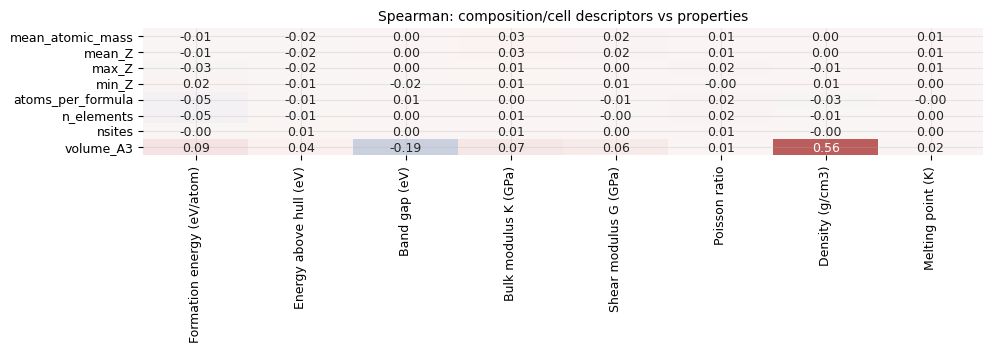

Grouped-CV R² of a pure category lookup (no composition at all):


,Formation energy (eV/atom),Energy above hull (eV),Band gap (eV),Bulk modulus K (GPa),Shear modulus G (GPa),Poisson ratio,Density (g/cm3),Melting point (K)
category mean,0.590,0.084,0.676,0.512,0.358,-0.004,0.255,0.358
category x crystal_system mean,0.581,0.067,0.671,0.501,0.348,-0.025,0.245,0.346


In [7]:
desc = ["mean_atomic_mass", "mean_Z", "max_Z", "min_Z", "atoms_per_formula", "n_elements", "nsites", "volume_A3"]
rs = pd.DataFrame({TARGETS[t]: {d: S.spearman_with_p(d1[d], d1[t])[0] for d in desc} for t in cols}).round(3)
rs.to_csv(TAB / "A4_descriptor_spearman.csv")
fig, ax = plt.subplots(figsize=(10, 3.6)); sns.heatmap(rs, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-.7, vmax=.7, ax=ax, cbar=False)
ax.set_title("Spearman: composition/cell descriptors vs properties"); savefig("A4_descriptor_spearman.png")

def cat_baseline_r2(df, target, keycol, groups, k=5):
    pred = np.full(len(df), np.nan)
    for tr, te in GroupKFold(k).split(df, groups=groups):
        mu = df.iloc[tr].groupby(keycol)[target].mean()
        pred[te] = df.iloc[te][keycol].map(mu).fillna(df.iloc[tr][target].mean()).values
    y = df[target].values; return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

d1["cat_x_cs"] = d1.category + "|" + d1.crystal_system
base = pd.DataFrame({TARGETS[t]: {"category mean": cat_baseline_r2(d1, t, "category", d1.formula),
                                  "category x crystal_system mean": cat_baseline_r2(d1, t, "cat_x_cs", d1.formula)} for t in cols}).round(3)
base.to_csv(TAB / "A4_category_baseline_cv_r2.csv"); print("Grouped-CV R² of a pure category lookup (no composition at all):"); display(base)
note("ds1_cat_baseline_R2_K", float(base.loc["category mean", TARGETS["bulk_modulus_GPa"]]), "grouped-CV R2 of category-mean lookup for K")
note("ds1_cat_baseline_R2_density", float(base.loc["category mean", TARGETS["density_g_cm3"]]), "grouped-CV R2 of category-mean lookup for density")

## A5 · Relationships among properties, and elastic-physics consistency
*Question: which property pairs are genuinely linked, and how far do (K, G, ν) deviate from isotropic elasticity ν = (3K−2G)/(2(3K+G))?
Also: Pugh's ratio K/G > 1.75 is the standard ductile/brittle indicator — relevant for later failure-mode reasoning.*

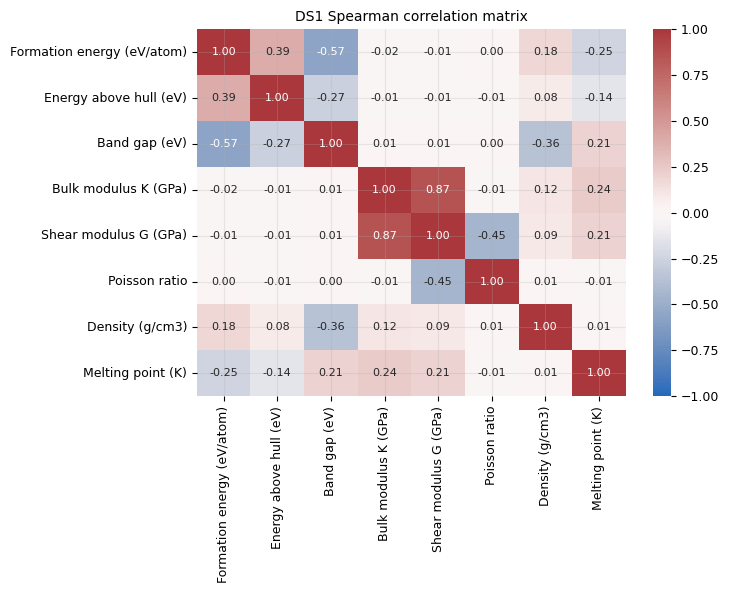

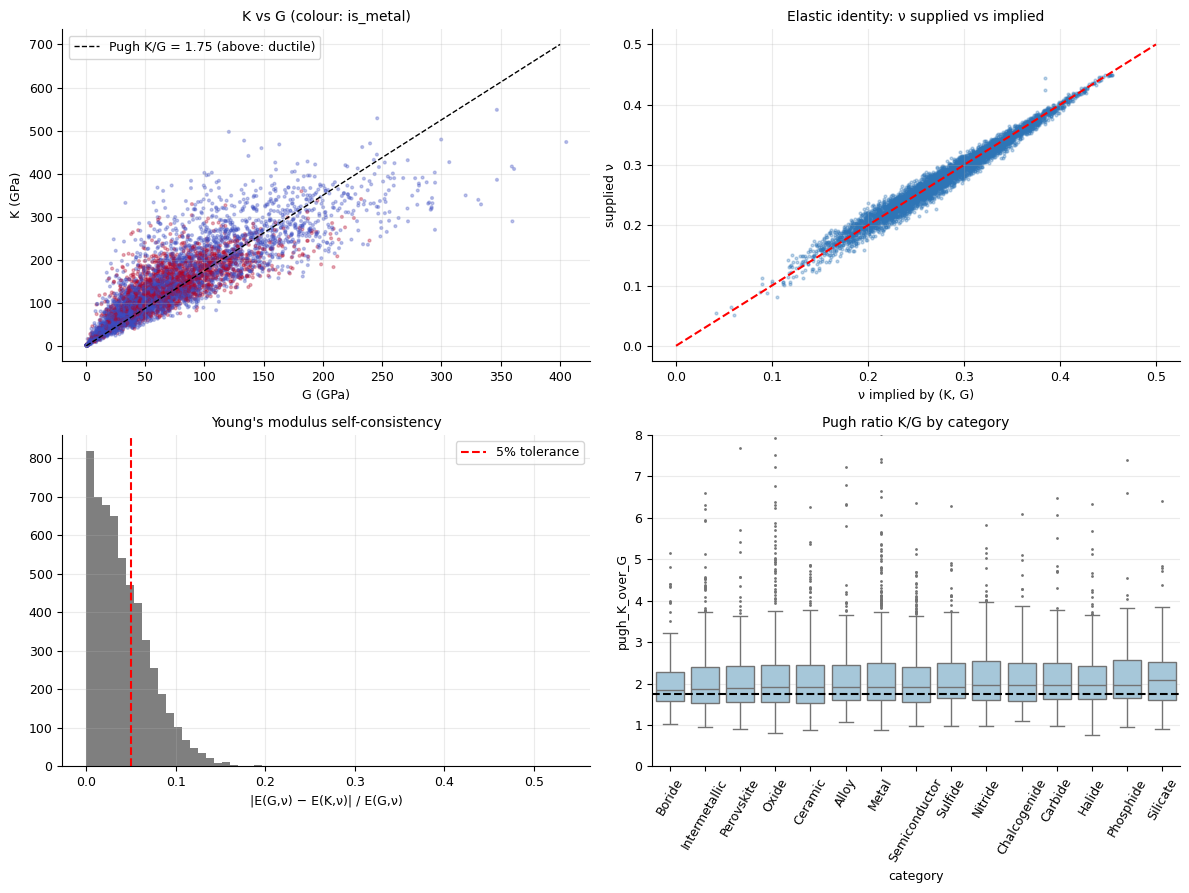

|ν − ν(K,G)|: median=0.0061, p95=0.0197 | share >0.01: 28.8%
E consistency: median rel. diff=0.034; share >5%: 33.5%
Pugh ratio K/G>1.75 (ductile by criterion): 62.9% of DS1
Spearman(K, G) = 0.865; Spearman(G, ν) = -0.451; theory: ν falls as G/K rises
Spearman(ν, G/K) = -0.986 | Spearman(ν_implied(K,G), G/K) = -1.0


In [8]:
sp = d1[cols].corr(method="spearman"); sp.index = sp.columns = [TARGETS[c] for c in cols]
fig, ax = plt.subplots(figsize=(7.5, 6)); sns.heatmap(sp, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8}); ax.set_title("DS1 Spearman correlation matrix")
savefig("A5_ds1_spearman.png")
K, G, nu = d1.bulk_modulus_GPa, d1.shear_modulus_GPa, d1.poisson_ratio
nu_kg = A._poisson_from_KG(K, G); E_g = 2 * G * (1 + nu); E_k = 3 * K * (1 - 2 * nu); relE = (E_g - E_k).abs() / E_g
d1["pugh_K_over_G"] = K / G
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
ax[0, 0].scatter(G, K, s=4, alpha=.3, c=d1.is_metal, cmap="coolwarm"); xx = np.linspace(0.5, 400, 50); ax[0, 0].plot(xx, 1.75 * xx, "k--", lw=1, label="Pugh K/G = 1.75 (above: ductile)")
ax[0, 0].set_xlabel("G (GPa)"); ax[0, 0].set_ylabel("K (GPa)"); ax[0, 0].legend(); ax[0, 0].set_title("K vs G (colour: is_metal)")
ax[0, 1].scatter(nu_kg, nu, s=4, alpha=.3, color="#2e75b6"); ax[0, 1].plot([0, .5], [0, .5], "r--"); ax[0, 1].set_xlabel("ν implied by (K, G)"); ax[0, 1].set_ylabel("supplied ν"); ax[0, 1].set_title("Elastic identity: ν supplied vs implied")
ax[1, 0].hist(relE.clip(upper=.6), bins=60, color="#7f7f7f"); ax[1, 0].axvline(.05, color="r", ls="--", label="5% tolerance"); ax[1, 0].legend(); ax[1, 0].set_xlabel("|E(G,ν) − E(K,ν)| / E(G,ν)"); ax[1, 0].set_title("Young's modulus self-consistency")
order = d1.groupby("category").pugh_K_over_G.median().sort_values().index
sns.boxplot(data=d1, x="category", y="pugh_K_over_G", order=order, ax=ax[1, 1], color="#9ecae1", fliersize=1); ax[1, 1].axhline(1.75, color="k", ls="--"); ax[1, 1].set_ylim(0, 8); ax[1, 1].tick_params(axis="x", rotation=60); ax[1, 1].set_title("Pugh ratio K/G by category")
savefig("A5_elasticity.png")
print(f"|ν − ν(K,G)|: median={np.abs(nu - nu_kg).median():.4f}, p95={np.abs(nu - nu_kg).quantile(.95):.4f} | share >0.01: {100*(np.abs(nu-nu_kg)>0.01).mean():.1f}%")
print(f"E consistency: median rel. diff={relE.median():.3f}; share >5%: {100*(relE>0.05).mean():.1f}%")
print(f"Pugh ratio K/G>1.75 (ductile by criterion): {100*(d1.pugh_K_over_G>1.75).mean():.1f}% of DS1")
print(f"Spearman(K, G) = {sps.spearmanr(K, G)[0]:.3f}; Spearman(G, ν) = {sps.spearmanr(G, nu)[0]:.3f}; theory: ν falls as G/K rises")
print("Spearman(ν, G/K) =", round(sps.spearmanr(nu, G / K)[0], 3), "| Spearman(ν_implied(K,G), G/K) =", round(sps.spearmanr(nu_kg, G / K)[0], 3))
note("ds1_E_inconsistent_gt5pct", float((relE > 0.05).mean()), "share of rows where E from (G,nu) and E from (K,nu) differ by >5%")
note("ds1_spearman_K_G", float(sps.spearmanr(K, G)[0]), "K-G rank correlation (physically expected to be strong)")
note("ds1_pugh_ductile_share", float((d1.pugh_K_over_G > 1.75).mean()), "share of DS1 with K/G>1.75 (Pugh ductile)")

## A6 · Stability label: is `is_stable` reproducible?
*Question: stability should follow thermodynamics (low energy above hull, negative formation energy). How well do those variables recover `is_stable`?*

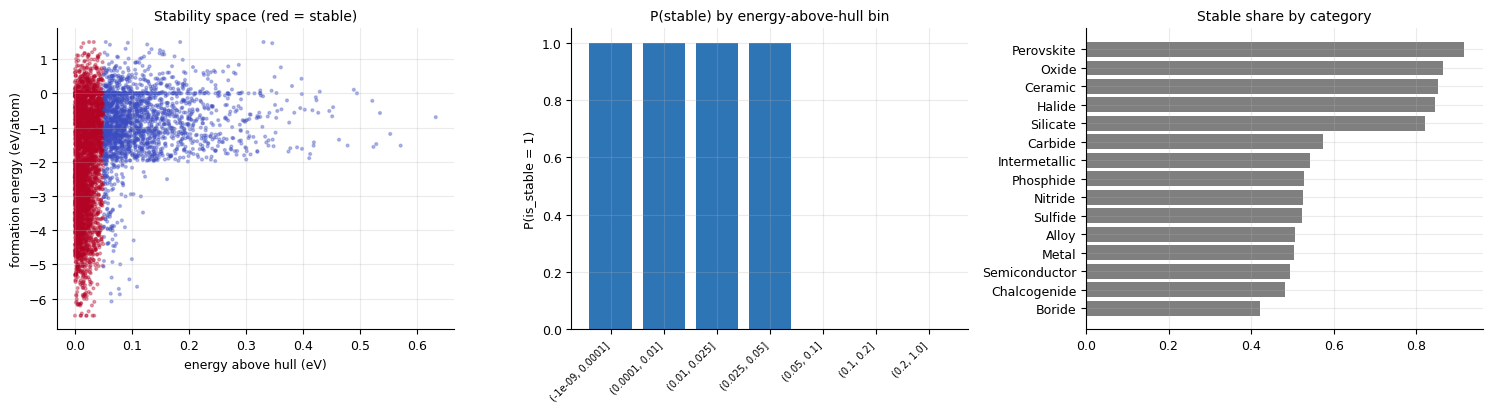

Ef<0,False,True
is_stable,,
0,389,1633
1,369,3109


AUC of −E_hull alone for is_stable: 1.000 | AUC of −formation energy alone: 0.713
Share of unstable rows with E_hull<=0.025: 0.0 | stable rows with E_hull>0.025: 0.318
is_stable==1 has E_hull in [0.0000, 0.0500]; is_stable==0 has E_hull in [0.0500, 0.6327]  ->  label is a deterministic threshold of E_hull


In [9]:
y = d1.is_stable
auc_h = roc_auc_score(y, -d1.energy_above_hull_eV); auc_e = roc_auc_score(y, -d1.formation_energy_per_atom_eV)
bins = pd.cut(d1.energy_above_hull_eV, [-1e-9, 0.0001, .01, .025, .05, .1, .2, 1]); pstab = d1.groupby(bins).is_stable.agg(["mean", "size"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(d1.energy_above_hull_eV, d1.formation_energy_per_atom_eV, s=4, alpha=.35, c=y, cmap="coolwarm"); ax[0].set_xlabel("energy above hull (eV)"); ax[0].set_ylabel("formation energy (eV/atom)"); ax[0].set_title("Stability space (red = stable)")
ax[1].bar(range(len(pstab)), pstab["mean"], color="#2e75b6"); ax[1].set_xticks(range(len(pstab))); ax[1].set_xticklabels([str(i) for i in pstab.index], rotation=45, ha="right", fontsize=7)
ax[1].set_ylabel("P(is_stable = 1)"); ax[1].set_title("P(stable) by energy-above-hull bin")
cs = d1.groupby("category").is_stable.mean().sort_values(); ax[2].barh(cs.index, cs.values, color="#7f7f7f"); ax[2].set_title("Stable share by category")
savefig("A6_stability.png")
ct = pd.crosstab(d1.is_stable, d1.formation_energy_per_atom_eV < 0, rownames=["is_stable"], colnames=["Ef<0"]); display(ct)
print(f"AUC of −E_hull alone for is_stable: {auc_h:.3f} | AUC of −formation energy alone: {auc_e:.3f}")
print("Share of unstable rows with E_hull<=0.025:", round(float(((y == 0) & (d1.energy_above_hull_eV <= .025)).sum() / (y == 0).sum()), 3), "| stable rows with E_hull>0.025:", round(float(((y == 1) & (d1.energy_above_hull_eV > .025)).sum() / (y == 1).sum()), 3))
smax, umin = d1.loc[y == 1, "energy_above_hull_eV"].max(), d1.loc[y == 0, "energy_above_hull_eV"].min()
print(f"is_stable==1 has E_hull in [{d1.loc[y==1,'energy_above_hull_eV'].min():.4f}, {smax:.4f}]; is_stable==0 has E_hull in [{umin:.4f}, {d1.loc[y==0,'energy_above_hull_eV'].max():.4f}]  ->  label is a deterministic threshold of E_hull")
note("ds1_is_stable_ehull_boundary", f"stable<= {smax:.4f}; unstable>= {umin:.4f}", "is_stable is a deterministic threshold of energy_above_hull (leakage if E_hull is a feature)")
note("ds1_auc_ehull_for_is_stable", float(auc_h), "AUC of -E_hull for is_stable")
note("ds1_auc_Ef_for_is_stable", float(auc_e), "AUC of -formation energy for is_stable")

## A7 · Cross-check against the workbook's reference materials
The workbook's DS-1 sheet holds a small table of well-known materials (Fe, Al, NaCl, …) with their *own* validation block.
*Question: do the CSV's inter-property relationships resemble those of the reference materials?* (Small sample ⇒ indicative only.)

In [10]:
ref = next(v for k, v in xl.items() if k.startswith("DS1_Material_Properties::block1")).copy()
cmap = {"Formation Energy": "Ef", "Band Gap": "gap", "Bulk Modulus": "K", "Shear Modulus": "G", "Poisson": "nu", "Density": "rho"}
ref = ref.rename(columns={c: v for c in ref.columns for k, v in cmap.items() if str(c).startswith(k)})
for c in cmap.values(): ref[c] = pd.to_numeric(ref[c], errors="coerce")
ref = ref.dropna(subset=["K", "G", "nu", "rho"]); print("reference materials with complete K, G, nu, density:", len(ref))
csv = d1.rename(columns={"formation_energy_per_atom_eV": "Ef", "band_gap_eV": "gap", "bulk_modulus_GPa": "K", "shear_modulus_GPa": "G", "poisson_ratio": "nu", "density_g_cm3": "rho"})
pairs = [("K", "G"), ("K", "rho"), ("G", "nu"), ("Ef", "gap"), ("rho", "gap")]
cmp_ = pd.DataFrame([{"pair": f"{a}~{b}", "reference_n": int(ref[[a, b]].dropna().shape[0]), "reference_spearman": ref[a].corr(ref[b], method="spearman"), "csv_spearman": csv[a].corr(csv[b], method="spearman")} for a, b in pairs]).round(3)
display(cmp_)
E_ref = (2 * ref.G * (1 + ref.nu) - 3 * ref.K * (1 - 2 * ref.nu)).abs() / (2 * ref.G * (1 + ref.nu))
print(f"Elastic self-consistency |E_G−E_K|/E_G: reference median={E_ref.median():.3f} (share>5%: {100*(E_ref>.05).mean():.0f}%) vs DS1 CSV median={relE.median():.3f} (share>5%: {100*(relE>.05).mean():.0f}%)")
print("Reference density range:", ref.rho.min(), "-", ref.rho.max(), "| CSV density range:", d1.density_g_cm3.min(), "-", d1.density_g_cm3.max())
note("ref_spearman_K_rho", float(ref.K.corr(ref.rho, method="spearman")), "reference materials: Spearman(K, density)")
note("csv_spearman_K_rho", float(csv.K.corr(csv.rho, method="spearman")), "DS1 CSV: Spearman(K, density)")
cmp_.to_csv(TAB / "A7_reference_vs_csv.csv", index=False)

reference materials with complete K, G, nu, density: 50


,pair,reference_n,reference_spearman,csv_spearman
0,K~G,50,0.891,0.865
1,K~rho,50,0.373,0.115
2,G~nu,50,-0.671,-0.451
3,Ef~gap,50,-0.788,-0.568
4,rho~gap,50,-0.577,-0.362


Elastic self-consistency |E_G−E_K|/E_G: reference median=0.020 (share>5%: 22%) vs DS1 CSV median=0.034 (share>5%: 33%)
Reference density range: 0.53 - 21.45 | CSV density range: 0.5 - 19.512


# PART B — DS3: infrastructure materials, degradation and condition
Derived variables created for analysis only (originals untouched): `thick_frac = remaining/original thickness`, `age_ratio = age/design_life`, `log_corr`.

In [11]:
d3["thick_frac"] = d3.remaining_thickness_mm / d3.original_thickness_mm
d3["age_ratio"] = d3.age_years / d3.design_life_years
d3["log_corr"] = np.log(d3.corrosion_rate_mm_yr)
d3["is_metal"] = d3.material.isin(A.METAL_MATERIALS_DS3)
inv = d3.groupby("material").agg(n=("bridge_id", "size"), age_median=("age_years", "median"), design_life_median=("design_life_years", "median"),
        corrosion_mm_yr_median=("corrosion_rate_mm_yr", "median"), thick_frac_median=("thick_frac", "median"), rating_mean=("condition_rating", "mean"),
        deficient_pct=("structurally_deficient", lambda s: 100 * s.mean()), beyond_design_life_pct=("age_ratio", lambda s: 100 * (s > 1).mean()),
        tensile_MPa=("tensile_strength_MPa", "median"), yield_MPa=("yield_strength_MPa", "median"), replacement_M_median=("replacement_cost_M", "median")).round(3)
inv.to_csv(TAB / "B1_material_inventory.csv"); display(inv.sort_values("rating_mean"))

,n,age_median,design_life_median,corrosion_mm_yr_median,thick_frac_median,rating_mean,deficient_pct,beyond_design_life_pct,tensile_MPa,yield_MPa,replacement_M_median
material,,,,,,,,,,,
Steel (A36),1232,48.0,75.0,0.055,0.864,6.766,7.873,15.260,450.0,250.0,0.460
Steel (A514 HY),283,48.0,75.0,0.053,0.865,6.788,9.187,14.134,760.0,690.0,0.510
Composite Steel-Concrete,410,45.0,75.0,0.057,0.954,6.822,8.049,12.439,400.0,230.0,0.495
Timber,229,46.0,75.0,0.045,0.927,7.253,1.747,11.354,8.0,5.0,0.500
Reinforced Concrete,977,45.0,75.0,0.029,0.977,7.831,0.205,12.692,25.0,20.0,0.460
Prestressed Concrete,921,46.0,75.0,0.028,0.979,7.848,0.000,10.641,35.0,28.0,0.460
Steel (A588 Weathering),486,46.0,75.0,0.027,0.932,7.907,0.000,10.905,485.0,345.0,0.470
Cast Iron,111,48.0,75.0,0.023,0.944,8.072,0.000,16.216,200.0,130.0,0.450
FRP Composite,106,43.5,75.0,0.020,0.968,8.132,0.000,16.981,600.0,500.0,0.470


## B1 · What determines the corrosion rate?
*Question: is corrosion driven by material, environment, location or structure type — and is the structure additive (log-linear) or does it need interactions?*

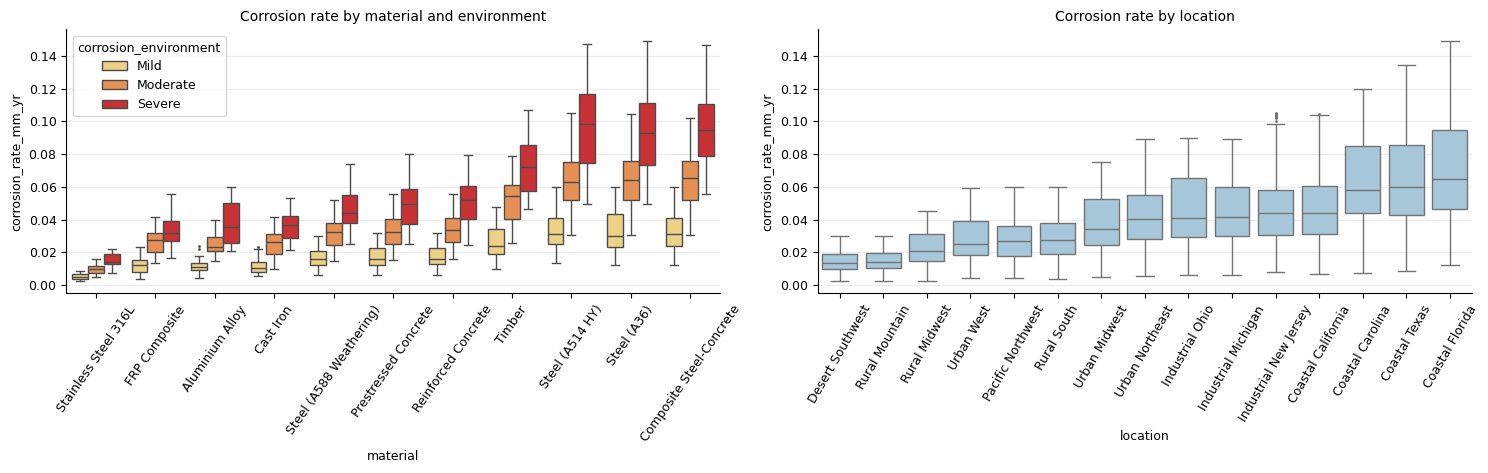

η² of log(corrosion rate):


,eta2
material,0.377
corrosion_environment,0.397
location,0.471
bridge_type,0.000


                                      adj R2  residual sd (log units)
material + environment                 0.769                    0.332
material + location                    0.852                    0.265
material x environment (interaction)   0.768                    0.332
material + environment + bridge_type   0.769                    0.332
Is environment a function of location? mean share of modal environment per location = 1.00 (1.0 = deterministic)


corrosion_environment,Mild,Moderate,Severe,Severe/Mild
material,,,,
Aluminium Alloy,0.0108,0.0232,0.0356,3.2765
Cast Iron,0.0103,0.0262,0.0365,3.5437
Composite Steel-Concrete,0.0312,0.0653,0.0946,3.0321
FRP Composite,0.0120,0.0274,0.0320,2.6556
Prestressed Concrete,0.0158,0.0323,0.0496,3.1392
Reinforced Concrete,0.0161,0.0339,0.0518,3.2205
Stainless Steel 316L,0.0052,0.0099,0.0142,2.7308
Steel (A36),0.0300,0.0643,0.0928,3.0950
Steel (A514 HY),0.0313,0.0632,0.0987,3.1534


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
order = d3.groupby("material").corrosion_rate_mm_yr.median().sort_values().index
sns.boxplot(data=d3, x="material", y="corrosion_rate_mm_yr", hue="corrosion_environment", order=order, hue_order=["Mild", "Moderate", "Severe"], ax=ax[0], fliersize=1, palette="YlOrRd")
ax[0].tick_params(axis="x", rotation=55); ax[0].set_title("Corrosion rate by material and environment")
lo = d3.groupby("location").corrosion_rate_mm_yr.median().sort_values().index
sns.boxplot(data=d3, x="location", y="corrosion_rate_mm_yr", order=lo, ax=ax[1], color="#9ecae1", fliersize=1); ax[1].tick_params(axis="x", rotation=60); ax[1].set_title("Corrosion rate by location")
savefig("B1_corrosion_drivers.png")
eta3 = pd.Series({g: S.eta_squared(d3.log_corr, d3[g]) for g in ["material", "corrosion_environment", "location", "bridge_type"]}).round(3)
print("η² of log(corrosion rate):"); display(eta3.to_frame("eta2"))
# environment is a function of location (shown just below), so material+environment+location would be rank-deficient: fit nested alternatives instead
m_env = smf.ols("log_corr ~ C(material) + C(corrosion_environment)", d3).fit()
m_loc = smf.ols("log_corr ~ C(material) + C(location)", d3).fit()
m_int = smf.ols("log_corr ~ C(material) * C(corrosion_environment)", d3).fit()
m_nofac = smf.ols("log_corr ~ C(material) + C(corrosion_environment) + C(bridge_type)", d3).fit()
print(pd.DataFrame({"adj R2": [m_env.rsquared_adj, m_loc.rsquared_adj, m_int.rsquared_adj, m_nofac.rsquared_adj], "residual sd (log units)": [np.sqrt(m.scale) for m in (m_env, m_loc, m_int, m_nofac)]},
      index=["material + environment", "material + location", "material x environment (interaction)", "material + environment + bridge_type"]).round(3))
purity = d3.groupby("location").corrosion_environment.agg(lambda s: s.value_counts(normalize=True).iloc[0])
print(f"Is environment a function of location? mean share of modal environment per location = {purity.mean():.2f} (1.0 = deterministic)")
pv = d3.pivot_table(index="material", columns="corrosion_environment", values="corrosion_rate_mm_yr", aggfunc="median")[["Mild", "Moderate", "Severe"]]
pv["Severe/Mild"] = pv.Severe / pv.Mild; display(pv.round(4))
note("ds3_corr_adjR2_material_env", float(m_env.rsquared_adj), "adj R2 of log corrosion ~ material + environment")
note("ds3_corr_adjR2_interaction", float(m_int.rsquared_adj), "adj R2 with material x environment interaction (equal => purely multiplicative)")
note("ds3_corr_resid_sd_log", float(np.sqrt(m_env.scale)), "residual sd of log corrosion after material + environment")
note("ds3_corr_eta2_material", float(eta3["material"]), "share of log-corrosion variance explained by material")
note("ds3_corr_eta2_env", float(eta3["corrosion_environment"]), "share explained by corrosion environment")
note("ds3_env_location_purity", float(purity.mean()), "mean share of modal corrosion_environment within a location")
note("ds3_severe_mild_ratio_median", float(pv["Severe/Mild"].median()), "median Severe/Mild corrosion ratio across materials (multiplicative structure)")

## B2 · What drives condition rating?
*Question: rating (NBI 9→1) vs age, corrosion, thinning and fatigue; how much is shared (collinear) given thickness loss ≡ corrosion × age (audit rule DS3-10)?*

,rho,p,n
driver,,,
age_years,-0.4321,0.0000,5000
age_ratio,-0.3723,0.0000,5000
corrosion_rate_mm_yr,-0.7030,0.0000,5000
thick_frac,0.6889,0.0000,5000
fatigue_cycles_millions,-0.1588,0.0000,5000
adt,-0.0110,0.4353,5000
tensile_strength_MPa,-0.0950,0.0000,5000
replacement_cost_M,0.0051,0.7177,5000


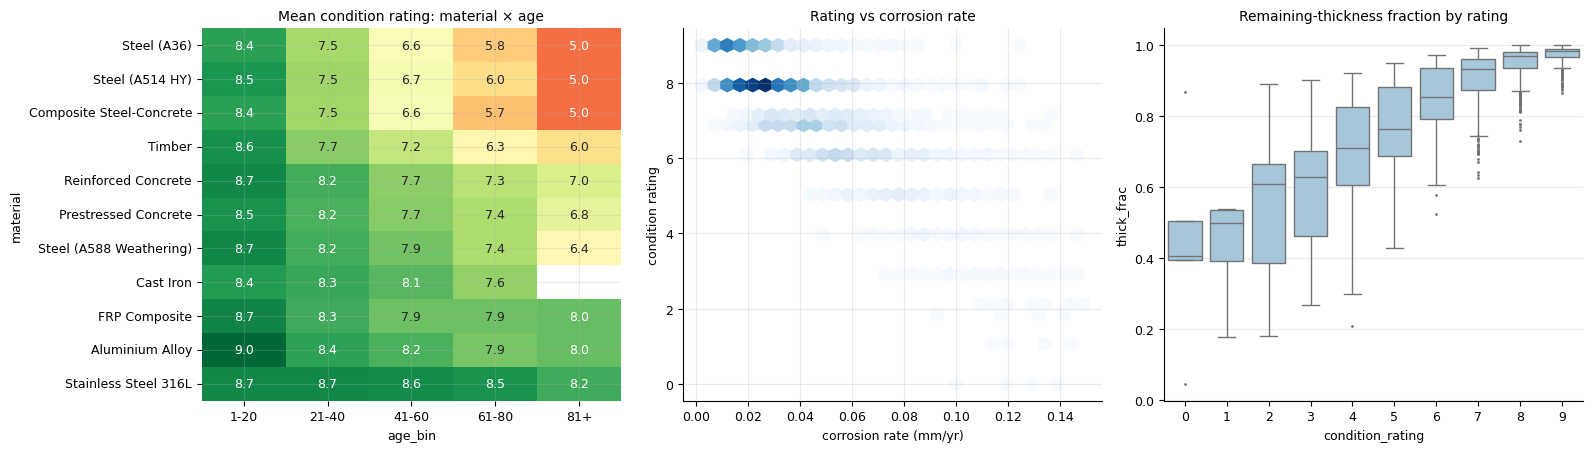

within-material Spearman(rating, corrosion): min=-0.70 median=-0.58 max=-0.36
                              adj R² (in-sample, explanatory)
age + corrosion                                         0.743
+ thickness fraction                                    0.757
+ age/design ratio + fatigue                            0.757
+ material dummies                                      0.767
VIF: {'z_age_years': np.float64(3.9), 'z_corrosion_rate_mm_yr': np.float64(2.1), 'z_thick_frac': np.float64(2.4), 'z_age_ratio': np.float64(3.6), 'z_fatigue_cycles_millions': np.float64(1.1)}
Standardised coefficients (full non-dummy model): {'Intercept': 7.454, 'z_age_years': -0.477, 'z_corrosion_rate_mm_yr': -0.818, 'z_thick_frac': 0.241, 'z_age_ratio': -0.008, 'z_fatigue_cycles_millions': -0.011}


In [13]:
drv = ["age_years", "age_ratio", "corrosion_rate_mm_yr", "thick_frac", "fatigue_cycles_millions", "adt", "tensile_strength_MPa", "replacement_cost_M"]
sp3 = pd.DataFrame([dict(zip(["rho", "p", "n"], S.spearman_with_p(d3[c], d3.condition_rating)), driver=c) for c in drv]).set_index("driver").round(4); display(sp3)
d3["age_bin"] = pd.cut(d3.age_years, [0, 20, 40, 60, 80, 105], labels=["1-20", "21-40", "41-60", "61-80", "81+"])
hm = d3.pivot_table(index="material", columns="age_bin", values="condition_rating", aggfunc="mean", observed=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
sns.heatmap(hm.loc[inv.sort_values("rating_mean").index], annot=True, fmt=".1f", cmap="RdYlGn", vmin=4, vmax=9, ax=ax[0], cbar=False); ax[0].set_title("Mean condition rating: material × age")
ax[1].hexbin(d3.corrosion_rate_mm_yr, d3.condition_rating, gridsize=30, cmap="Blues", mincnt=1); ax[1].set_xlabel("corrosion rate (mm/yr)"); ax[1].set_ylabel("condition rating"); ax[1].set_title("Rating vs corrosion rate")
sns.boxplot(data=d3, x="condition_rating", y="thick_frac", ax=ax[2], color="#9ecae1", fliersize=1); ax[2].set_title("Remaining-thickness fraction by rating")
savefig("B2_condition_drivers.png")
within = d3.groupby("material").apply(lambda g: S.spearman_with_p(g.corrosion_rate_mm_yr, g.condition_rating)[0])
print(f"within-material Spearman(rating, corrosion): min={within.min():.2f} median={within.median():.2f} max={within.max():.2f}")
z = lambda s: (s - s.mean()) / s.std()
for c in ["age_years", "corrosion_rate_mm_yr", "thick_frac", "age_ratio", "fatigue_cycles_millions"]: d3["z_" + c] = z(d3[c])
mods = {"age + corrosion": "condition_rating ~ z_age_years + z_corrosion_rate_mm_yr",
        "+ thickness fraction": "condition_rating ~ z_age_years + z_corrosion_rate_mm_yr + z_thick_frac",
        "+ age/design ratio + fatigue": "condition_rating ~ z_age_years + z_corrosion_rate_mm_yr + z_thick_frac + z_age_ratio + z_fatigue_cycles_millions",
        "+ material dummies": "condition_rating ~ z_age_years + z_corrosion_rate_mm_yr + z_thick_frac + z_age_ratio + z_fatigue_cycles_millions + C(material)"}
fits = {k: smf.ols(f, d3).fit() for k, f in mods.items()}
print(pd.Series({k: round(f.rsquared_adj, 3) for k, f in fits.items()}, name="adj R² (in-sample, explanatory)").to_frame())
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = d3[["z_age_years", "z_corrosion_rate_mm_yr", "z_thick_frac", "z_age_ratio", "z_fatigue_cycles_millions"]].assign(const=1.0)
print("VIF:", {c: round(variance_inflation_factor(X.values, i), 1) for i, c in enumerate(X.columns) if c != "const"})
print("Standardised coefficients (full non-dummy model):", fits["+ age/design ratio + fatigue"].params.round(3).to_dict())
note("ds3_rating_spearman_corrosion", float(sp3.loc["corrosion_rate_mm_yr", "rho"]), "Spearman(rating, corrosion rate)")
note("ds3_rating_spearman_thickfrac", float(sp3.loc["thick_frac", "rho"]), "Spearman(rating, remaining thickness fraction)")
note("ds3_rating_spearman_age", float(sp3.loc["age_years", "rho"]), "Spearman(rating, age)")
note("ds3_rating_adjR2_full", float(fits["+ age/design ratio + fatigue"].rsquared_adj), "adj R2 of rating on age, corrosion, thinning, age ratio, fatigue")

## B3 · Fatigue exposure
*Question: is `fatigue_cycles_millions` an independent measurement or a function of traffic × age? Does it relate to condition in metals (where Paris-law crack growth applies)?*

fatigue cycles / (ADT·365·age/1e6): median=1.00, IQR=[1.00, 1.00], within ±10%: 81.5%
Spearman(fatigue cycles, ADT·365·age) = 0.935
Metals only: Spearman(rating, fatigue) = -0.153; rating vs paris_m: +0.005


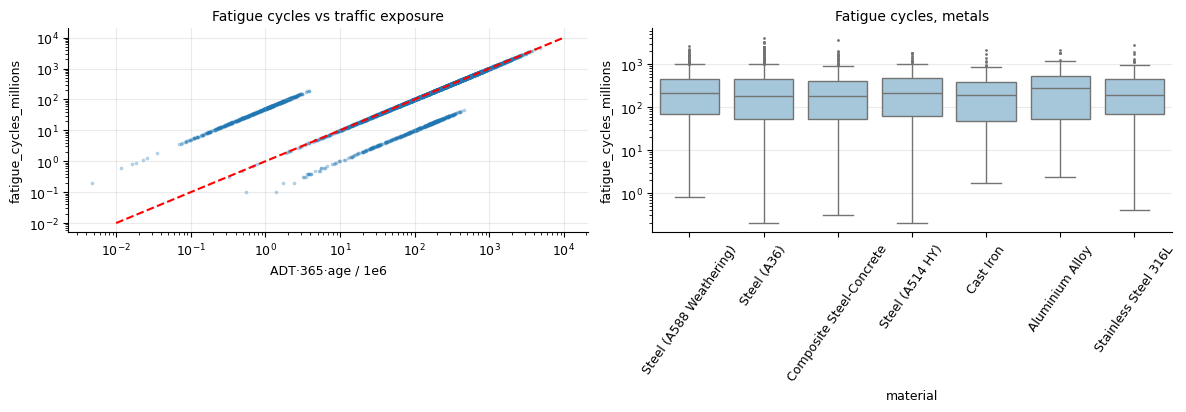

paris_C                             paris_m            
                                   min        median           max     min median  max
material                                                                              
Aluminium Alloy           5.000000e-12  5.000000e-12  5.000000e-12     3.1    3.1  3.1
Cast Iron                 1.200000e-11  1.200000e-11  1.200000e-11     3.8    3.8  3.8
Composite Steel-Concrete  6.500000e-12  6.500000e-12  6.500000e-12     3.0    3.0  3.0
Stainless Steel 316L      3.100000e-12  3.100000e-12  3.100000e-12     3.2    3.2  3.2
Steel (A36)               6.900000e-12  6.900000e-12  6.900000e-12     3.0    3.0  3.0
Steel (A514 HY)           4.500000e-12  4.500000e-12  4.500000e-12     3.2    3.2  3.2
Steel (A588 Weathering)   5.200000e-12  5.200000e-12  5.200000e-12     2.8    2.8  2.8

Paris constants vary within a material: False -> they are per-material constants, not asset-level measurements


In [14]:
implied = d3.adt * 365 * d3.age_years / 1e6; fr = d3.fatigue_cycles_millions / implied
print(f"fatigue cycles / (ADT·365·age/1e6): median={fr.median():.2f}, IQR=[{fr.quantile(.25):.2f}, {fr.quantile(.75):.2f}], within ±10%: {100*(fr.sub(1).abs()<.1).mean():.1f}%")
print(f"Spearman(fatigue cycles, ADT·365·age) = {sps.spearmanr(d3.fatigue_cycles_millions, implied)[0]:.3f}")
met = d3[d3.is_metal]; print(f"Metals only: Spearman(rating, fatigue) = {sps.spearmanr(met.condition_rating, met.fatigue_cycles_millions)[0]:+.3f}; rating vs paris_m: {sps.spearmanr(met.condition_rating, met.paris_m)[0]:+.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(implied, d3.fatigue_cycles_millions, s=3, alpha=.25); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].plot([1e-2, 1e4], [1e-2, 1e4], "r--"); ax[0].set_xlabel("ADT·365·age / 1e6"); ax[0].set_ylabel("fatigue_cycles_millions"); ax[0].set_title("Fatigue cycles vs traffic exposure")
sns.boxplot(data=met, x="material", y="fatigue_cycles_millions", ax=ax[1], color="#9ecae1", fliersize=1); ax[1].set_yscale("log"); ax[1].tick_params(axis="x", rotation=55); ax[1].set_title("Fatigue cycles, metals")
savefig("B3_fatigue.png")
pm = d3[d3.is_metal].groupby("material")[["paris_C", "paris_m"]].agg(["min", "median", "max"]); display(pm)
print("Paris constants vary within a material:", bool((d3[d3.is_metal].groupby("material")[["paris_C", "paris_m"]].nunique() > 1).any().any()), "-> they are per-material constants, not asset-level measurements")
note("ds3_fatigue_within10_of_adt_age", float((fr.sub(1).abs() < .1).mean()), "share of bridges where fatigue cycles equal ADT*365*age within 10%")

## B4 · How close are assets to a critical thickness?
The CSV has no critical thickness. The workbook's 10-asset table gives *wall (or cover) thickness* and *critical thickness*; their ratio is the only documented
reference for a "critical" fraction. We use that **range** (not a single assumed value) purely descriptively.
*Question: what share of bridges already sit below the workbook's critical ratios, and how many years of corrosion remain to reach them?*

Workbook critical/original thickness ratios (10 assets): min=0.417, median=0.455, max=0.500


,n,thick_frac_median,pct_below_lo,pct_below_hi,yrs_to_hi_median
material,,,,,
Aluminium Alloy,93,0.97,0.00,0.00,600.00
Cast Iron,111,0.94,0.00,0.00,322.99
Composite Steel-Concrete,410,0.95,0.00,0.00,434.77
FRP Composite,106,0.97,0.00,0.00,550.18
Prestressed Concrete,921,0.98,0.00,0.00,953.44
Reinforced Concrete,977,0.98,0.00,0.00,897.14
Stainless Steel 316L,152,0.98,0.00,0.00,1010.10
Steel (A36),1232,0.86,1.54,2.84,110.94
Steel (A514 HY),283,0.87,1.77,2.47,119.23


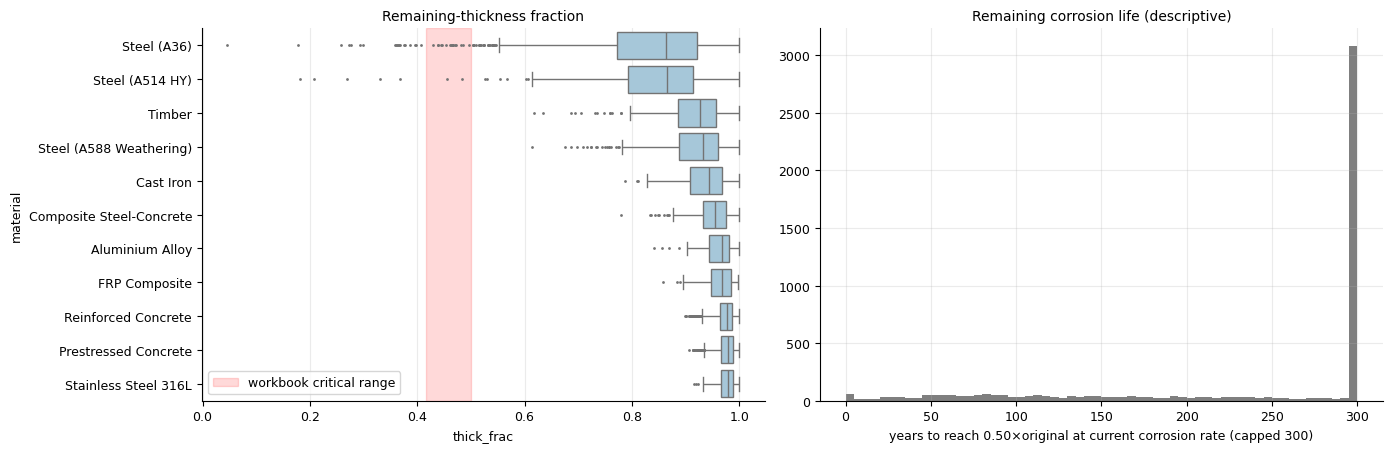

Share already below critical ratio: 0.5% (ratio 0.417) to 0.8% (ratio 0.500); median years remaining (hi ratio): 436
Rating of bridges already below the high critical ratio vs others: {False: 7.49, True: 3.05}


In [15]:
pt = next(v for k, v in xl.items() if "MATERIAL PROPERTIES FOR PORTFOLIO" in k)
crit = (pt["Critical Thickness (mm)"] / pt["Wall/Cover Thickness (mm)"]).astype(float)
CR_LO, CR_HI = float(crit.min()), float(crit.max()); print(f"Workbook critical/original thickness ratios (10 assets): min={CR_LO:.3f}, median={crit.median():.3f}, max={CR_HI:.3f}")
for lab, r in (("lo", CR_LO), ("hi", CR_HI)):
    d3[f"yrs_to_crit_{lab}"] = ((d3.remaining_thickness_mm - r * d3.original_thickness_mm) / d3.corrosion_rate_mm_yr).clip(lower=0)
    d3[f"below_crit_{lab}"] = d3.thick_frac < r
tab = d3.groupby("material").agg(n=("bridge_id", "size"), thick_frac_median=("thick_frac", "median"), pct_below_lo=("below_crit_lo", lambda s: 100 * s.mean()),
        pct_below_hi=("below_crit_hi", lambda s: 100 * s.mean()), yrs_to_hi_median=("yrs_to_crit_hi", "median")).round(2); tab.to_csv(TAB / "B4_critical_thickness_exposure.csv"); display(tab)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
order = d3.groupby("material").thick_frac.median().sort_values().index
sns.boxplot(data=d3, y="material", x="thick_frac", order=order, ax=ax[0], color="#9ecae1", fliersize=1); ax[0].axvspan(CR_LO, CR_HI, color="red", alpha=.15, label="workbook critical range"); ax[0].legend(); ax[0].set_title("Remaining-thickness fraction")
ax[1].hist(d3.yrs_to_crit_hi.clip(upper=300), bins=60, color="#7f7f7f"); ax[1].set_xlabel(f"years to reach {CR_HI:.2f}×original at current corrosion rate (capped 300)"); ax[1].set_title("Remaining corrosion life (descriptive)")
savefig("B4_critical_thickness.png")
print(f"Share already below critical ratio: {100*d3.below_crit_lo.mean():.1f}% (ratio {CR_LO:.3f}) to {100*d3.below_crit_hi.mean():.1f}% (ratio {CR_HI:.3f}); median years remaining (hi ratio): {d3.yrs_to_crit_hi.median():.0f}")
print("Rating of bridges already below the high critical ratio vs others:", d3.groupby("below_crit_hi").condition_rating.mean().round(2).to_dict())
note("ds3_pct_below_crit_hi", float(d3.below_crit_hi.mean()), "share of DS3 bridges with thickness fraction below the workbook's highest critical ratio")
note("ds3_crit_ratio_range", f"{CR_LO:.3f}-{CR_HI:.3f}", "workbook critical/original thickness ratio range (10 assets)")

# PART C — DS6: what do historical failures look like?
Remember: DS6 has **failures only**. Part C describes failure *mechanisms and severity*; Part C5 compares failures with the DS3 population as a **preview** of the case-control design (an assumption, flagged below).
## C1 · Composition of the failure record

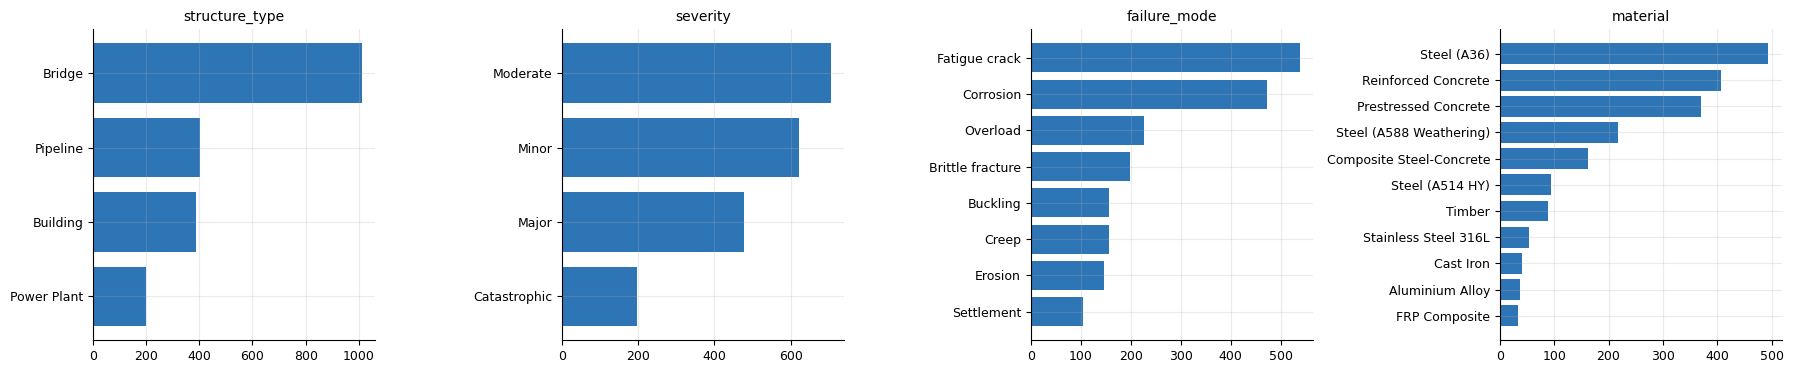

                n  loss_ratio_median  repair_cost_median  claim_rate  regulatory_rate
severity                                                                             
Catastrophic  196              0.948           1051926.0       0.658            0.648
Major         477              0.490            508735.0       0.660            0.564
Minor         622              0.049             56014.5       0.693            0.000
Moderate      705              0.200            213678.0       0.726            0.000


In [16]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, c in zip(ax, ["structure_type", "severity", "failure_mode", "material"]):
    vc = d6[c].value_counts(); a.barh(vc.index[::-1], vc.values[::-1], color="#2e75b6"); a.set_title(c)
savefig("C1_failure_composition.png")
print(d6.groupby("severity").agg(n=("event_id", "size"), loss_ratio_median=("loss_ratio", "median"), repair_cost_median=("repair_cost_USD", "median"), claim_rate=("insurance_claim_filed", "mean"), regulatory_rate=("regulatory_action", "mean")).round(3))

## C2 · Are failure modes physically linked to materials, structures and environment?
*Question: if mechanics mattered, fatigue/brittle fracture would concentrate in metals, creep in high-temperature plant, settlement in concrete foundations, corrosion in steel in severe environments. Cramér's V measures association (0 = independent).*

,cramers_V,chi2,p
pair,,,
failure_mode ~ material,0.0286,81.4136,0.1654
failure_mode ~ structure_type,0.0056,21.1951,0.4471
failure_mode ~ corrosion_environment,0.0450,22.1043,0.0765
severity ~ structure_type,0.0071,9.3070,0.4094
severity ~ failure_mode,0.0000,9.8441,0.9809
severity ~ material,0.0030,30.0690,0.4621
severity ~ corrosion_environment,0.0403,12.4981,0.0517
material ~ structure_type,0.0000,25.0315,0.7235


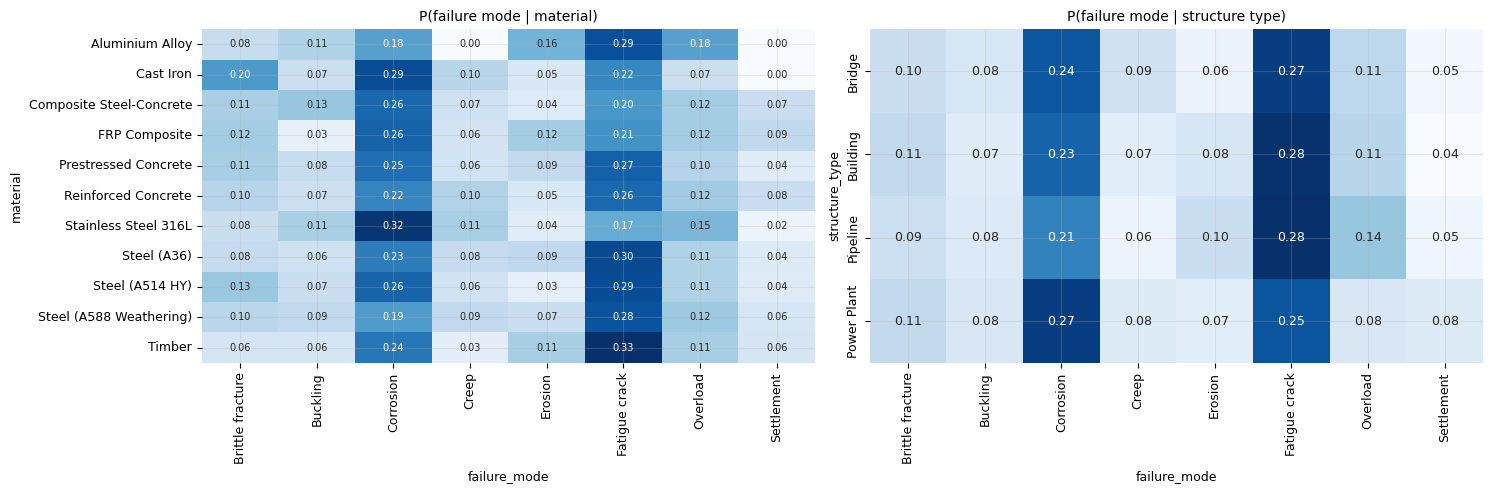

Physically questionable pairs: corrosion failures in FRP composite: 9 (26% of FRP failures); creep in timber: 3 | fatigue cracks in timber: 29 | buckling in cast iron: 3


In [17]:
pairs = [("failure_mode", "material"), ("failure_mode", "structure_type"), ("failure_mode", "corrosion_environment"), ("severity", "structure_type"),
         ("severity", "failure_mode"), ("severity", "material"), ("severity", "corrosion_environment"), ("material", "structure_type")]
cv = pd.DataFrame([dict(zip(["cramers_V", "chi2", "p"], S.cramers_v(d6[a], d6[b])), pair=f"{a} ~ {b}") for a, b in pairs]).set_index("pair").round(4); cv.to_csv(TAB / "C2_failure_associations.csv"); display(cv)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(pd.crosstab(d6.material, d6.failure_mode, normalize="index"), annot=True, fmt=".2f", cmap="Blues", ax=ax[0], cbar=False, annot_kws={"size": 7}); ax[0].set_title("P(failure mode | material)")
sns.heatmap(pd.crosstab(d6.structure_type, d6.failure_mode, normalize="index"), annot=True, fmt=".2f", cmap="Blues", ax=ax[1], cbar=False); ax[1].set_title("P(failure mode | structure type)")
savefig("C2_mode_by_material.png")
fm = pd.crosstab(d6.material, d6.failure_mode); print("Physically questionable pairs: corrosion failures in FRP composite:", int(fm.loc["FRP Composite", "Corrosion"]), f"({100*fm.loc['FRP Composite','Corrosion']/fm.loc['FRP Composite'].sum():.0f}% of FRP failures);",
      "creep in timber:", int(fm.loc["Timber", "Creep"]), "| fatigue cracks in timber:", int(fm.loc["Timber", "Fatigue crack"]), "| buckling in cast iron:", int(fm.loc["Cast Iron", "Buckling"]))
note("ds6_V_mode_material", float(cv.loc["failure_mode ~ material", "cramers_V"]), "Cramer's V failure_mode vs material")
note("ds6_V_mode_structure", float(cv.loc["failure_mode ~ structure_type", "cramers_V"]), "Cramer's V failure_mode vs structure_type")
note("ds6_V_severity_mode", float(cv.loc["severity ~ failure_mode", "cramers_V"]), "Cramer's V severity vs failure_mode")
note("ds6_p_mode_material", float(cv.loc["failure_mode ~ material", "p"]), "chi2 independence p-value, mode vs material")

## C3 · Age and corrosion at failure: do they separate modes and severities?

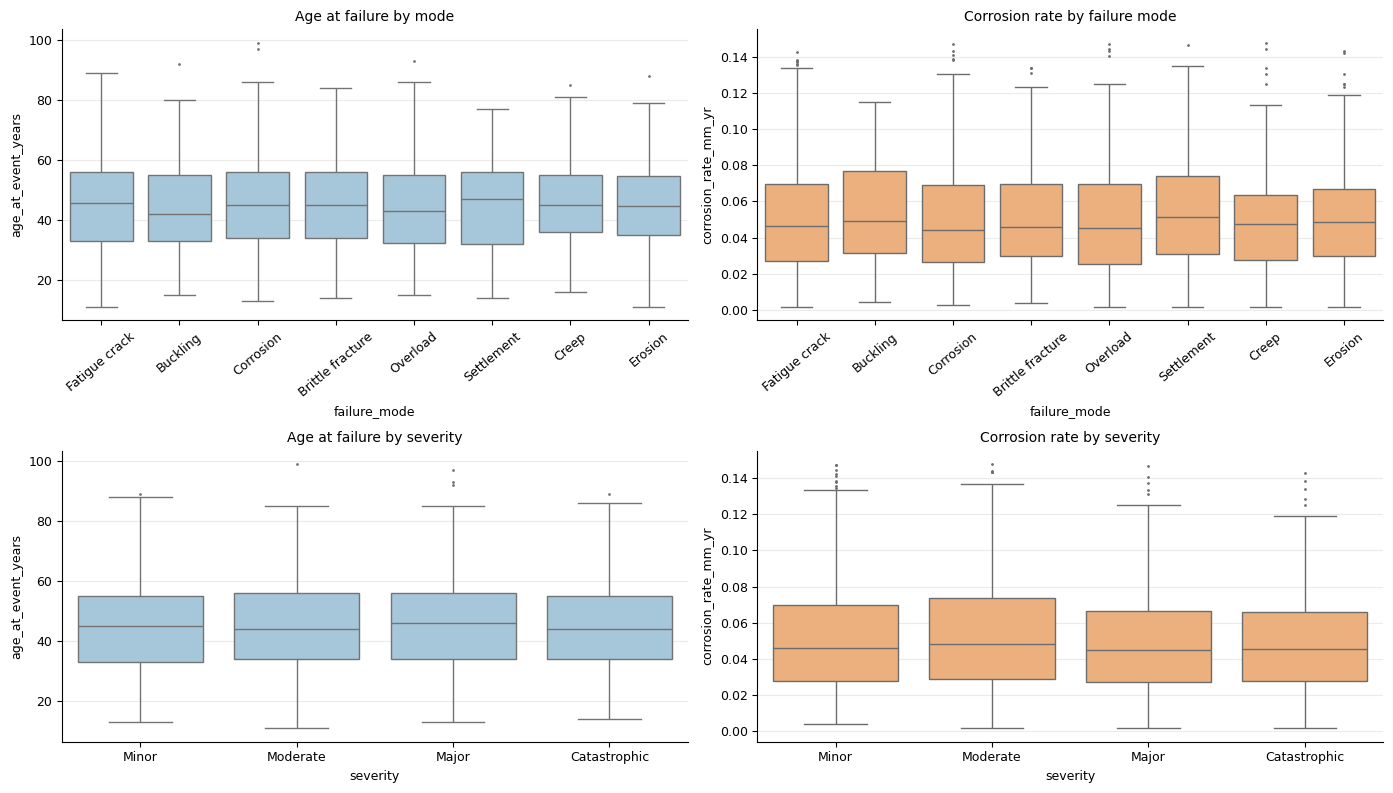

,epsilon2,p,q
test,,,
age_at_event_years ~ failure_mode,0.0000,0.7476,0.8673
corrosion_rate_mm_yr ~ failure_mode,0.0000,0.7588,0.8673
age_at_event_years ~ severity,0.0000,0.9539,0.9539
corrosion_rate_mm_yr ~ severity,0.0009,0.1797,0.3822
age_at_event_years ~ material,0.0000,0.5299,0.8478
corrosion_rate_mm_yr ~ material,0.1717,0.0000,0.0000
corrosion_rate_mm_yr ~ corrosion_environment,0.4649,0.0000,0.0000
age_at_event_years ~ structure_type,0.0009,0.1911,0.3822


Spearman(age at failure, corrosion rate) in DS6: 0.042 | in DS3 population: 0.009
Per-material corrosion rate, DS3 population vs DS6 failures (Spearman across materials = 0.18):


,DS3_median_corr,DS6_median_corr,ratio
material,,,
Aluminium Alloy,0.0216,0.0626,2.8981
Cast Iron,0.0230,0.0547,2.3783
Composite Steel-Concrete,0.0566,0.0476,0.8402
FRP Composite,0.0201,0.0359,1.7886
Prestressed Concrete,0.0276,0.0512,1.8533
Reinforced Concrete,0.0287,0.0524,1.8258
Stainless Steel 316L,0.0083,0.0070,0.8434
Steel (A36),0.0552,0.0482,0.8740
Steel (A514 HY),0.0533,0.0600,1.1257


In [18]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
sns.boxplot(data=d6, x="failure_mode", y="age_at_event_years", ax=ax[0, 0], color="#9ecae1", fliersize=1); ax[0, 0].tick_params(axis="x", rotation=40); ax[0, 0].set_title("Age at failure by mode")
sns.boxplot(data=d6, x="failure_mode", y="corrosion_rate_mm_yr", ax=ax[0, 1], color="#fdae6b", fliersize=1); ax[0, 1].tick_params(axis="x", rotation=40); ax[0, 1].set_title("Corrosion rate by failure mode")
so = ["Minor", "Moderate", "Major", "Catastrophic"]
sns.boxplot(data=d6, x="severity", y="age_at_event_years", order=so, ax=ax[1, 0], color="#9ecae1", fliersize=1); ax[1, 0].set_title("Age at failure by severity")
sns.boxplot(data=d6, x="severity", y="corrosion_rate_mm_yr", order=so, ax=ax[1, 1], color="#fdae6b", fliersize=1); ax[1, 1].set_title("Corrosion rate by severity")
savefig("C3_age_corrosion_by_mode_severity.png")
tests = [("age_at_event_years", "failure_mode"), ("corrosion_rate_mm_yr", "failure_mode"), ("age_at_event_years", "severity"), ("corrosion_rate_mm_yr", "severity"),
         ("age_at_event_years", "material"), ("corrosion_rate_mm_yr", "material"), ("corrosion_rate_mm_yr", "corrosion_environment"), ("age_at_event_years", "structure_type")]
kt = pd.DataFrame([dict(zip(["epsilon2", "p"], S.kruskal_epsilon2(d6[v], d6[g])), test=f"{v} ~ {g}") for v, g in tests]).set_index("test"); kt["q"] = S.bh_fdr(kt.p); kt = kt.round(4); kt.to_csv(TAB / "C3_kruskal_effects.csv"); display(kt)
print("Spearman(age at failure, corrosion rate) in DS6:", round(sps.spearmanr(d6.age_at_event_years, d6.corrosion_rate_mm_yr)[0], 3), "| in DS3 population:", round(sps.spearmanr(d3.age_years, d3.corrosion_rate_mm_yr)[0], 3))
cmpm = pd.DataFrame({"DS3_median_corr": d3.groupby("material").corrosion_rate_mm_yr.median(), "DS6_median_corr": d6.groupby("material").corrosion_rate_mm_yr.median()}); cmpm["ratio"] = cmpm.DS6_median_corr / cmpm.DS3_median_corr
print("Per-material corrosion rate, DS3 population vs DS6 failures (Spearman across materials = %.2f):" % sps.spearmanr(cmpm.DS3_median_corr, cmpm.DS6_median_corr)[0]); display(cmpm.round(4))
note("ds6_eps2_corr_by_environment", float(kt.loc["corrosion_rate_mm_yr ~ corrosion_environment", "epsilon2"]), "epsilon2: DS6 corrosion rate by environment")
note("ds6_eps2_corr_by_mode", float(kt.loc["corrosion_rate_mm_yr ~ failure_mode", "epsilon2"]), "epsilon2: DS6 corrosion rate by failure mode")
note("ds6_eps2_age_by_severity", float(kt.loc["age_at_event_years ~ severity", "epsilon2"]), "epsilon2: DS6 age by severity")
note("ds6_eps2_corr_by_severity", float(kt.loc["corrosion_rate_mm_yr ~ severity", "epsilon2"]), "epsilon2: DS6 corrosion by severity")

## C4 · Failure frequency over time
*Question: are events a stationary Poisson-like stream (relevant for annual-loss modelling), or trending/clustered?*

events/year: mean=105.3, sd=11.0; dispersion index var/mean=1.15 (Poisson = 1); chi2 dispersion test p=0.296
trend: Spearman(year, count) = +0.35 (p=0.15)


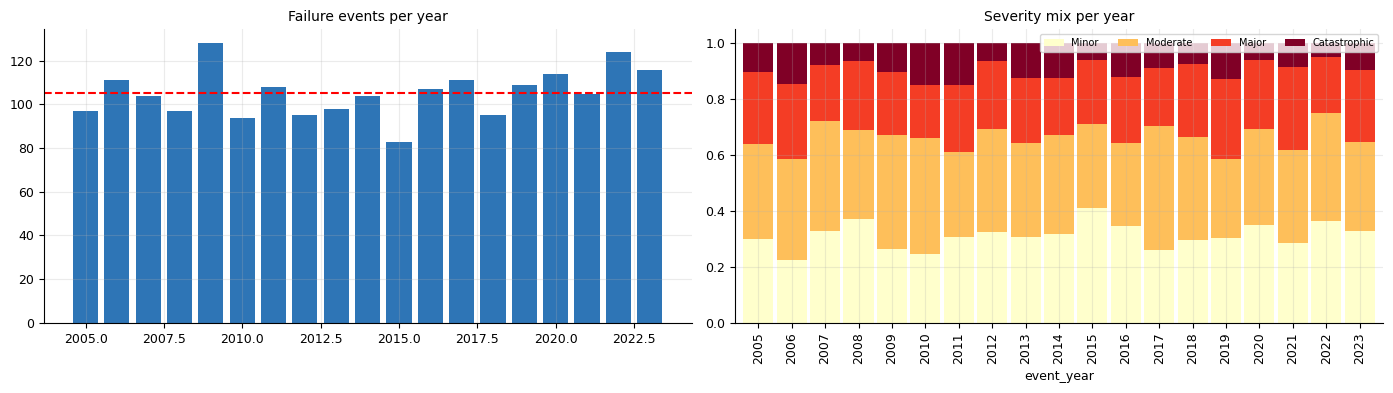

In [19]:
yr = d6.groupby("event_year").size(); disp = yr.var(ddof=1) / yr.mean(); dstat = (len(yr) - 1) * disp; dp = 1 - sps.chi2.cdf(dstat, len(yr) - 1)
rho_t = sps.spearmanr(yr.index, yr.values)
print(f"events/year: mean={yr.mean():.1f}, sd={yr.std():.1f}; dispersion index var/mean={disp:.2f} (Poisson = 1); chi2 dispersion test p={dp:.3f}")
print(f"trend: Spearman(year, count) = {rho_t[0]:+.2f} (p={rho_t[1]:.2f})")
mix = pd.crosstab(d6.event_year, d6.severity, normalize="index")[so]
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); ax[0].bar(yr.index, yr.values, color="#2e75b6"); ax[0].axhline(yr.mean(), color="r", ls="--"); ax[0].set_title("Failure events per year")
mix.plot.bar(stacked=True, ax=ax[1], colormap="YlOrRd", width=.9); ax[1].set_title("Severity mix per year"); ax[1].legend(fontsize=7, ncol=4)
savefig("C4_failures_over_time.png")
note("ds6_dispersion_index", float(disp), "variance/mean of annual event counts (Poisson=1)")
note("ds6_events_per_year_mean", float(yr.mean()), "mean DS6 events per year")

## C5 · Failures vs the at-risk population (case-control preview)
**Assumption under test (not established by the data):** DS3's 5,000 bridges are representative of the population that generated DS6's 1,011 *bridge* failures.
If failures arise from risk factors, the case distribution should differ from the population distribution in those factors. Only bridges are compared;
buildings, pipelines and power plants have no DS3 counterpart.
*Question: which materials / environments / ages / corrosion rates are over-represented among failures?*

DS6 bridge failures: 1011 | DS3 population: 5000
chi-square goodness of fit (failure mix vs population mix): material p=0.391 | environment p=0.813 | location p=0.687


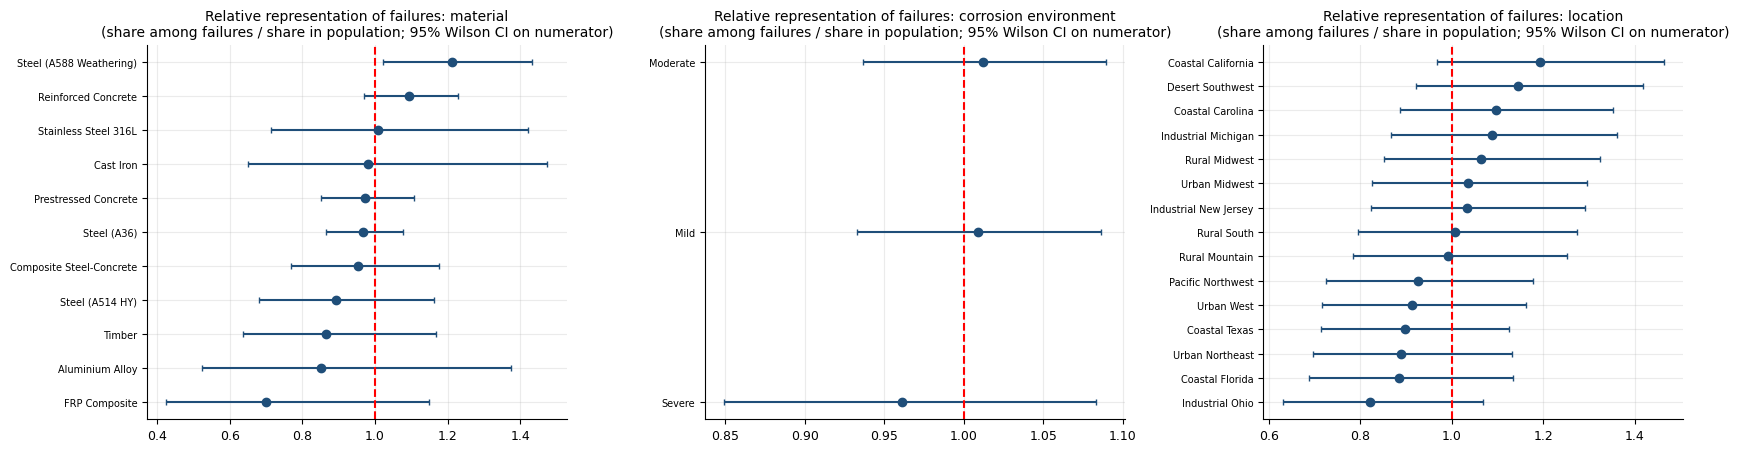

,fail_n,pop_n,fail_share,pop_share,RR,RR_lo,RR_hi
material,,,,,,,
FRP Composite,15,106,0.015,0.021,0.700,0.425,1.148
Aluminium Alloy,16,93,0.016,0.019,0.851,0.525,1.374
Timber,40,229,0.040,0.046,0.864,0.637,1.167
Steel (A514 HY),51,283,0.050,0.057,0.891,0.682,1.161
Composite Steel-Concrete,79,410,0.078,0.082,0.953,0.770,1.175
Steel (A36),241,1232,0.238,0.246,0.967,0.865,1.078
Prestressed Concrete,181,921,0.179,0.184,0.972,0.850,1.107
Cast Iron,22,111,0.022,0.022,0.980,0.649,1.474
Stainless Steel 316L,31,152,0.031,0.030,1.009,0.713,1.421


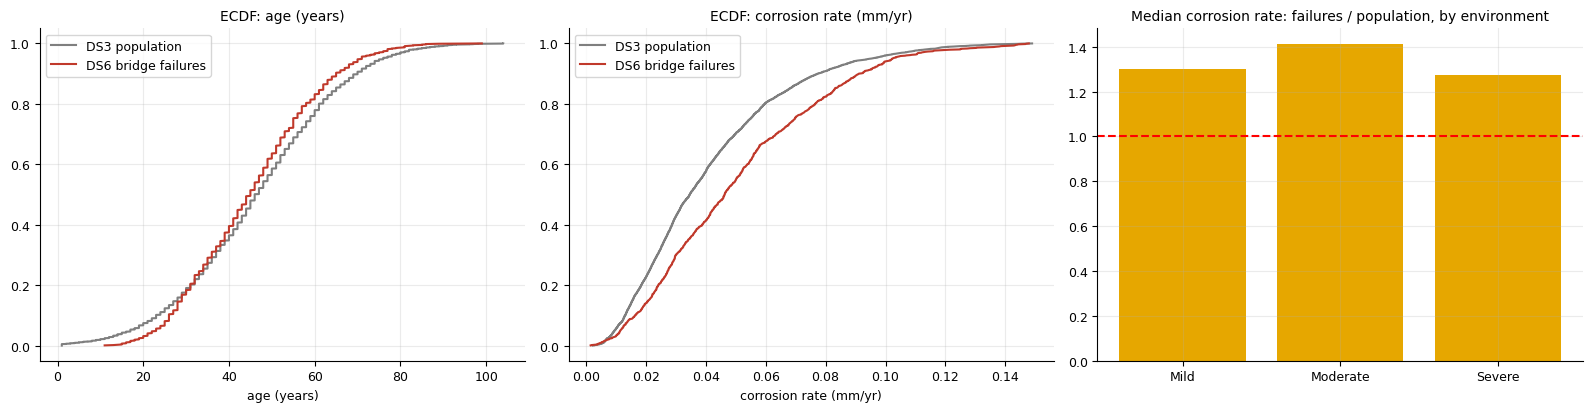

,DS3_pop,DS6_fail,fail/pop
corrosion_environment,,,
Mild,0.0206,0.0268,1.3010
Moderate,0.0406,0.0573,1.4113
Severe,0.0600,0.0766,1.2758


single-feature separability (AUC, failures vs population): age=0.475 (KS=0.070, p=0.000535) | corrosion rate=0.603 (KS=0.169, p=1.94e-21)


In [20]:
b6 = d6[d6.structure_type == "Bridge"].copy(); print("DS6 bridge failures:", len(b6), "| DS3 population:", len(d3))
def share_table(col):
    t = pd.DataFrame({"fail_n": b6[col].value_counts(), "pop_n": d3[col].value_counts()}).fillna(0)
    nf, npop = t.fail_n.sum(), t.pop_n.sum(); t["fail_share"] = t.fail_n / nf; t["pop_share"] = t.pop_n / npop; t["RR"] = t.fail_share / t.pop_share
    ci = [S.wilson_ci(int(k), int(nf)) for k in t.fail_n]; t["RR_lo"] = [c[0] for c in ci] / t.pop_share; t["RR_hi"] = [c[1] for c in ci] / t.pop_share
    chi = sps.chisquare(t.fail_n, f_exp=t.pop_share * nf); return t.sort_values("RR"), chi
tm, chm = share_table("material"); te, che = share_table("corrosion_environment"); tl, chl = share_table("location")
print(f"chi-square goodness of fit (failure mix vs population mix): material p={chm.pvalue:.3g} | environment p={che.pvalue:.3g} | location p={chl.pvalue:.3g}")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, t, ttl in zip(ax, (tm, te, tl), ("material", "corrosion environment", "location")):
    a.errorbar(t.RR, range(len(t)), xerr=[t.RR - t.RR_lo, t.RR_hi - t.RR], fmt="o", color="#1f4e79", capsize=2); a.axvline(1, color="r", ls="--"); a.set_yticks(range(len(t))); a.set_yticklabels(t.index, fontsize=7); a.set_title(f"Relative representation of failures: {ttl}\n(share among failures / share in population; 95% Wilson CI on numerator)")
savefig("C5_relative_representation.png")
tm.round(3).to_csv(TAB / "C5_material_relative_representation.csv"); display(tm.round(3))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (c3, c6, lab) in zip(ax, [("age_years", "age_at_event_years", "age (years)"), ("corrosion_rate_mm_yr", "corrosion_rate_mm_yr", "corrosion rate (mm/yr)")]):
    for s, nme, col in ((d3[c3], "DS3 population", "#7f7f7f"), (b6[c6], "DS6 bridge failures", "#c0392b")):
        x = np.sort(s.values); a.plot(x, np.arange(1, len(x) + 1) / len(x), label=nme, color=col)
    a.set_xlabel(lab); a.set_title(f"ECDF: {lab}"); a.legend()
env_ratio = pd.concat([d3.groupby("corrosion_environment").corrosion_rate_mm_yr.median(), b6.groupby("corrosion_environment").corrosion_rate_mm_yr.median()], axis=1, keys=["DS3_pop", "DS6_fail"]); env_ratio["fail/pop"] = env_ratio.DS6_fail / env_ratio.DS3_pop
ax[2].bar(env_ratio.index, env_ratio["fail/pop"], color="#e6a700"); ax[2].axhline(1, color="r", ls="--"); ax[2].set_title("Median corrosion rate: failures / population, by environment")
savefig("C5_case_vs_population.png"); display(env_ratio.round(4))
y = np.r_[np.ones(len(b6)), np.zeros(len(d3))]
auc_age = roc_auc_score(y, np.r_[b6.age_at_event_years, d3.age_years]); auc_cor = roc_auc_score(y, np.r_[b6.corrosion_rate_mm_yr, d3.corrosion_rate_mm_yr])
ks_age = sps.ks_2samp(b6.age_at_event_years, d3.age_years); ks_cor = sps.ks_2samp(b6.corrosion_rate_mm_yr, d3.corrosion_rate_mm_yr)
print(f"single-feature separability (AUC, failures vs population): age={auc_age:.3f} (KS={ks_age.statistic:.3f}, p={ks_age.pvalue:.3g}) | corrosion rate={auc_cor:.3f} (KS={ks_cor.statistic:.3f}, p={ks_cor.pvalue:.3g})")
note("c5_auc_age", float(auc_age), "AUC of age separating DS6 bridge failures from DS3 population")
note("c5_auc_corrosion", float(auc_cor), "AUC of corrosion rate separating DS6 bridge failures from DS3 population")
note("c5_chi2_p_material", float(chm.pvalue), "chi-square GOF p: failure material mix vs population")
note("c5_chi2_p_environment", float(che.pvalue), "chi-square GOF p: failure environment mix vs population")
note("c5_chi2_p_location", float(chl.pvalue), "chi-square GOF p: failure location mix vs population")
note("c5_corr_ratio_fail_pop_median", float(env_ratio["fail/pop"].median()), "median over environments of failure/population corrosion-rate ratio")
note("c5_rr_max_material", f"{tm.RR.idxmax()} ({tm.RR.max():.2f})", "most over-represented material among failures")
note("c5_rr_min_material", f"{tm.RR.idxmin()} ({tm.RR.min():.2f})", "most under-represented material among failures")

## Key computed findings (printed from the run; also saved to `outputs/tables/material_eda_key_findings.csv`)

In [21]:
kf = pd.DataFrame([{"finding": k, "value": (round(v["value"], 4) if isinstance(v["value"], float) else v["value"]), "meaning": v["meaning"]} for k, v in KEY.items()])
kf.to_csv(TAB / "material_eda_key_findings.csv", index=False)
pd.set_option("display.max_colwidth", 120); display(kf)

,finding,value,meaning
0,ds1_density_share_at_floor,0.023,share of rows piled at the minimum density (value clipped at a bound -> censored)
1,ds1_G_share_at_floor,0.001,share of rows piled at the minimum shear modulus
2,ds1_band_gap_zero_share,0.3253,share of DS1 with band gap exactly 0 (metals) -> two-part target (metal flag + gap)
3,ds1_eta2_category_K,0.514,variance of K explained by category
4,ds1_eta2_category_density,0.259,variance of density explained by category
5,ds1_eta2_category_Ef,0.592,variance of formation energy explained by category
6,ds1_oxide_contains_O,0.038,share of 'Oxide' rows whose formula contains oxygen
7,ds1_median_label_lift,1.031,median lift of chemistry rules inside category vs elsewhere (1 = no information)
8,ds1_density_within10pct_of_physics,0.0467,share of rows whose density is within 10% of density implied by composition and volume
9,ds1_nsites_multiple_of_formula,0.3056,share of rows where nsites is an integer multiple of the reduced-formula atom count


## What the material EDA establishes (every number is from the cells above)

### Part A — DS1 compounds
1. **Properties are organised by `category`, not by composition.** Category alone explains 51% of K, 59% of formation energy, 68% of band gap, 36% of G and melting point, 26% of density (η²), and a pure category lookup reaches grouped-CV R² of 0.51 (K), 0.59 (E_f), 0.68 (gap), 0.36 (G, T_m), 0.26 (density). Crystal system, `n_elements` explain ≈0%.
2. **Composition carries no detectable signal.** 0 of 496 element×property tests are significant after FDR (largest |δ| = 0.145, below the "small" threshold of 0.147); heavier elements do **not** raise density (Spearman(Z, δ_density) = +0.05, p = 0.69).
3. **The density identity fails.** Only 4.7% of rows are within ±10% of the density implied by composition and cell volume; supplied density vs mean atomic mass has Spearman 0.004; only 30.6% of rows have `nsites` as an integer multiple of the formula's atom count.
4. **Category labels split into two kinds.** The *electronic* ones are exact (Metal/Alloy/Intermetallic: 100% `is_metal`; Semiconductor: 100% with 0 < gap ≤ 4 eV; Ceramic: 100% gap > 0). The *chemistry-named* ones carry no chemistry (only 3.8% of "Oxides" contain O, 0% of "Silicates" contain Si and O; median lift 1.03).
5. **Elastic behaviour is internally coherent despite violating the README identity.** K–G Spearman 0.865 (workbook reference materials: 0.891); supplied ν is almost a monotone function of G/K (Spearman −0.986). The README violations (28.8% of ν off by >0.01, 33.5% of E off by >5%) are *noise around a coherent relationship*, which justifies deriving ν and E from (K, G). By Pugh's criterion 62.9% of DS1 is ductile (K/G > 1.75).
6. **`is_stable` is a deterministic threshold of `energy_above_hull`** (stable: E_hull ∈ [0, 0.05]; unstable: ≥ 0.05). It is not a free target — E_hull must never be a feature for it. Formation energy alone reaches AUC 0.71; the README's "stable ⇒ E_f < 0" does not describe the label.
7. **Values are partly censored at bounds:** 2.3% of densities sit at 0.5, 1.2% of K at 2.0, 1.6% of T_m at 200 K; 32.5% of band gaps are exactly 0 (metals).
8. **Relative to the workbook's real reference materials the CSV is weaker** (K~density ρ 0.12 vs 0.37; E_f~gap −0.57 vs −0.79; elastic self-consistency median 3.4% vs 2.0%).

### Part B — DS3 bridges
1. **Corrosion rate is almost fully structured:** material + environment explain adj. R² = 0.77 of log-rate, material + location 0.85; adding a material×environment interaction gains nothing (0.768) ⇒ the effect is **multiplicative** (Severe/Mild median ratio ≈ 3.1, range 2.7–3.5). `corrosion_environment` is a deterministic function of `location`; `bridge_type` has η² = 0.000.
2. **Condition rating is explained by corrosion and age:** Spearman −0.70 (corrosion), +0.69 (thickness fraction), −0.43 (age); age + corrosion alone reach adj. R² = 0.74; thickness fraction adds 0.014; age/design-life ratio, fatigue and material add ≤ 0.01. Thickness is derived from corrosion × age (audit DS3-10), so it is redundant by construction.
3. **Fatigue cycles are not an independent measurement:** they equal ADT×365×age/10⁶ (median ratio 1.00; 81.5% within ±10%). Paris constants are per-material constants (zero within-material variance), so they add nothing beyond material identity.
4. **Physical thinning rarely reaches criticality.** Using the workbook's critical/original thickness range (0.417–0.500), only 0.5–0.8% of bridges are already below it (almost all A36/A514 steel; their mean rating is 3.05 vs 7.49 for the rest); median years remaining to the upper ratio is ≈ 436 (≈ 900 for concrete, where the thickness variable is a cover thickness of unclear meaning). **A purely thickness-based physical PD would be ≈ 0 for >99% of assets**, so it cannot be the main PD driver.

### Part C — DS6 failures
1. **Failure mode is statistically independent of material, structure type and environment** (Cramér's V ≤ 0.045, all p > 0.07) and severity is independent of mode, material and structure (V ≤ 0.04). No physical mode–material coupling is visible (e.g. 9 of the 34 FRP-composite failures, 26%, are recorded as *corrosion*, a mechanism FRP does not undergo).
2. **Severity is a fixed mixture, and it fully determines the loss ratio bands:** Minor 622 events (loss ratio 0.025–0.075), Moderate 705 (0.10–0.30), Major 477 (0.25–0.75), Catastrophic 196 (0.516–1.464) of 2,000; the mix is flat across structure types (catastrophic share 8–12%). Regulatory action occurs only for Major/Catastrophic; claims are filed in ≈ 66–73% of events at every severity.
3. **Neither age nor corrosion at failure separates modes or severities** (ε² ≤ 0.001). Corrosion rate in DS6 depends on environment (ε² = 0.46) and material (ε² = 0.17), exactly as in DS3 — the two datasets share a generating structure.
4. **Failure counts behave like a stationary Poisson stream:** 105.3 events/yr, dispersion index 1.15 (p = 0.30), no significant trend (ρ = +0.35, p = 0.15).
5. **Case-control preview.** Failure mix equals population mix in material, environment and location (χ² GOF p = 0.39 / 0.81 / 0.69; the largest deviation, A588 weathering steel RR = 1.21 [1.02, 1.43], is one of 11 uncorrected comparisons). The **only** separating variable is corrosion rate: failures run ≈ 1.3× the population median in every environment (1.30 / 1.41 / 1.28), AUC = 0.60; age has AUC = 0.475.

### Consequences for the next stages
* **Material model:** DS1 is a stand-alone module. The honest benchmark is the category-lookup R²; a composition model that fails to beat it must be reported as such. Predict K and G, derive ν and E; treat `is_stable` as a thresholded E_hull and do not use E_hull as a feature for it; handle bounds/zeros (metal flag + gap).
* **Failure model:** the case-control relative-risk model has one real driver (corrosion rate, via environment/material/location). Expected discrimination is **AUC ≈ 0.60**, and it will be reported as such. Condition rating (explained by corrosion + age) is the usable degradation state / "material health" ingredient.
* **Loss given failure:** LGD cannot be conditioned on material or degradation (severity is independent of them); it is the empirical severity mixture with its loss-ratio bands (both capped and uncapped variants).
* **Event frequency** is Poisson-compatible, which supports an annual-loss (frequency × severity) formulation.